# Customer Churn Prediction and Retention Analysis

## End-to-End Machine Learning Project

**Objective:** Develop a machine learning solution to predict customer churn, identify high-risk customers, and generate actionable customer retention strategies.

### Project Workflow
1. Data Understanding and Data Quality Audit
2. Exploratory Data Analysis (EDA)
3. Data Cleaning and Feature Engineering
4. Machine Learning Model Development
5. Model Optimization and Evaluation
6. Model Explainability
7. Customer Retention Intervention Simulation
8. Business Recommendations and Conclusions

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 120)

# Visualization settings
sns.set_theme(style="whitegrid")

# Random seed for reproducibility
RANDOM_STATE = 42

print("Libraries imported successfully!")

Libraries imported successfully!


In [4]:
# Locate the project root
PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

# Dataset path
DATA_PATH = PROJECT_ROOT / "data" / "raw" / "customer_churn_advanced_dataset.csv"

# Load CSV file
df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

Dataset loaded successfully!
Dataset shape: (1200, 20)


In [5]:
df.head()

,customer_id,age,tenure_months,contract_type,internet_service,region,monthly_charges,total_charges,payment_method,paperless_billing,dependents,support_plan,tech_support,complaints_last_12m,late_payments_last_12m,satisfaction_score,monthly_usage_gb,discount_pct,senior_citizen,churn
0,CUST100001,23,64,One year,Fiber optic,Eastern,48.36,3082.83,Mailed check,No,No,No,No,0,0,6.2,16.4,5.61,0,1
1,CUST100002,62,35,One year,DSL,Central,51.34,1585.19,Electronic check,Yes,No,Yes,No,1,1,7.4,38.1,0.00,0,1
2,CUST100003,55,71,Month-to-month,DSL,North Central,130.98,8564.89,Bank transfer,No,No,No,No,0,1,8.2,NaN,22.92,0,1
3,CUST100004,43,55,Month-to-month,Fiber optic,Western,115.24,6390.85,Credit card,Yes,No,No,No,0,1,9.8,70.1,9.66,0,1
4,CUST100005,43,47,Month-to-month,Fiber optic,Sabaragamuwa,62.12,2540.63,Electronic check,Yes,No,No,No,3,0,8.5,144.2,11.20,0,1


In [6]:
print("DATASET INFORMATION")
print("=" * 50)

df.info()

print("\nDATASET DIMENSIONS")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

print("\nCOLUMN NAMES")
print(df.columns.tolist())

DATASET INFORMATION
<class 'pandas.DataFrame'>
RangeIndex: 1200 entries, 0 to 1199
Data columns (total 20 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   customer_id             1200 non-null   str    
 1   age                     1200 non-null   int64  
 2   tenure_months           1200 non-null   int64  
 3   contract_type           1200 non-null   str    
 4   internet_service        1200 non-null   str    
 5   region                  1200 non-null   str    
 6   monthly_charges         1170 non-null   float64
 7   total_charges           1176 non-null   float64
 8   payment_method          1200 non-null   str    
 9   paperless_billing       1200 non-null   str    
 10  dependents              1200 non-null   str    
 11  support_plan            1200 non-null   str    
 12  tech_support            1200 non-null   str    
 13  complaints_last_12m     1200 non-null   int64  
 14  late_payments_last_12m  1200 no

## 1. Data Quality Audit

### Objective
The objective of this stage is to evaluate the quality and reliability of the customer churn dataset before preprocessing and machine learning.

The following checks are performed:

1. Missing value analysis
2. Duplicate record detection
3. Data type verification
4. Categorical value inspection
5. Invalid value detection
6. Outlier detection
7. Target variable distribution

All detected issues will be documented before selecting appropriate cleaning techniques.

In [7]:
# ==========================================
# 1.1 Missing Value Analysis
# ==========================================

missing_summary = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing Percentage": (df.isnull().mean() * 100).round(2)
})

missing_summary = missing_summary[
    missing_summary["Missing Count"] > 0
].sort_values("Missing Count", ascending=False)

print("MISSING VALUE SUMMARY")
display(missing_summary)

print("\nTotal missing cells:", df.isnull().sum().sum())

MISSING VALUE SUMMARY


,Missing Count,Missing Percentage
satisfaction_score,48,4.0
monthly_usage_gb,36,3.0
monthly_charges,30,2.5
total_charges,24,2.0



Total missing cells: 138


In [8]:
# ==========================================
# 1.2 Duplicate Record Detection
# ==========================================

duplicate_rows = df.duplicated().sum()

duplicate_ids = df["customer_id"].duplicated().sum()

print("Duplicate rows:", duplicate_rows)
print("Duplicate customer IDs:", duplicate_ids)
print("Unique customers:", df["customer_id"].nunique())

Duplicate rows: 0
Duplicate customer IDs: 0
Unique customers: 1200


In [9]:
# ==========================================
# 1.3 Categorical Variable Inspection
# ==========================================

categorical_columns = df.select_dtypes(
    include=["object", "category"]
).columns

for col in categorical_columns:

    print(f"\nCOLUMN: {col}")
    print("-" * 40)

    print(df[col].value_counts(dropna=False))


COLUMN: customer_id
----------------------------------------
customer_id
CUST100001    1
CUST100002    1
CUST100003    1
CUST100004    1
CUST100005    1
             ..
CUST101196    1
CUST101197    1
CUST101198    1
CUST101199    1
CUST101200    1
Name: count, Length: 1200, dtype: int64

COLUMN: contract_type
----------------------------------------
contract_type
Month-to-month    708
One year          303
Two year          189
Name: count, dtype: int64

COLUMN: internet_service
----------------------------------------
internet_service
Fiber optic    621
DSL            430
No             149
Name: count, dtype: int64

COLUMN: region
----------------------------------------
region
Western          147
Central          144
Northern         138
Eastern          136
Southern         136
Uva              130
North Central    126
Sabaragamuwa     125
North Western    118
Name: count, dtype: int64

COLUMN: payment_method
----------------------------------------
payment_method
Electronic che

C:\Users\Wasika\AppData\Local\Temp\ipykernel_12660\2765683009.py:5: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = df.select_dtypes(


In [10]:
# ==========================================
# 1.4 Invalid Value Detection
# ==========================================

invalid_checks = {
    "Negative age": (df["age"] < 0).sum(),

    "Negative tenure": (df["tenure_months"] < 0).sum(),

    "Negative monthly charges":
        (df["monthly_charges"] < 0).sum(),

    "Negative total charges":
        (df["total_charges"] < 0).sum(),

    "Negative complaints":
        (df["complaints_last_12m"] < 0).sum(),

    "Negative late payments":
        (df["late_payments_last_12m"] < 0).sum(),

    "Invalid satisfaction score":
        (
            df["satisfaction_score"].notna()
            & ~df["satisfaction_score"].between(1, 10)
        ).sum(),

    "Negative monthly usage":
        (df["monthly_usage_gb"] < 0).sum(),

    "Invalid discount percentage":
        (~df["discount_pct"].between(0, 100)).sum(),

    "Invalid senior citizen flag":
        (~df["senior_citizen"].isin([0, 1])).sum(),

    "Invalid churn label":
        (~df["churn"].isin([0, 1])).sum()
}

invalid_summary = pd.DataFrame(
    list(invalid_checks.items()),
    columns=["Validation Check", "Invalid Count"]
)

display(invalid_summary)

,Validation Check,Invalid Count
0,Negative age,0
1,Negative tenure,0
2,Negative monthly charges,0
3,Negative total charges,0
4,Negative complaints,0
5,Negative late payments,0
6,Invalid satisfaction score,0
7,Negative monthly usage,0
8,Invalid discount percentage,0
9,Invalid senior citizen flag,0


In [11]:
# ==========================================
# 1.5 Outlier Detection Using IQR
# ==========================================

numerical_columns = [
    "age",
    "tenure_months",
    "monthly_charges",
    "total_charges",
    "complaints_last_12m",
    "late_payments_last_12m",
    "satisfaction_score",
    "monthly_usage_gb",
    "discount_pct"
]

outlier_results = []

for col in numerical_columns:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[
        (df[col] < lower_bound) |
        (df[col] > upper_bound)
    ]

    outlier_results.append({
        "Feature": col,
        "Outlier Count": len(outliers),
        "Lower Bound": round(lower_bound, 2),
        "Upper Bound": round(upper_bound, 2)
    })

outlier_summary = pd.DataFrame(outlier_results)

display(outlier_summary)

,Feature,Outlier Count,Lower Bound,Upper Bound
0,age,0,-11.50,104.50
1,tenure_months,0,-36.00,108.00
2,monthly_charges,12,5.62,135.82
3,total_charges,14,-2829.97,7701.22
4,complaints_last_12m,41,-1.50,2.50
5,late_payments_last_12m,57,-1.50,2.50
6,satisfaction_score,4,2.00,11.60
7,monthly_usage_gb,5,-31.05,161.55
8,discount_pct,2,-11.60,28.87


In [12]:
# ==========================================
# 1.6 Target Variable Distribution
# ==========================================

target_counts = df["churn"].value_counts().sort_index()
target_percentages = (
    df["churn"].value_counts(normalize=True)
    .sort_index() * 100
).round(2)

target_summary = pd.DataFrame({
    "Customer Count": target_counts,
    "Percentage": target_percentages
})

display(target_summary)

print("Total customers:", len(df))
print("Overall churn rate:", round(df["churn"].mean() * 100, 2), "%")

,Customer Count,Percentage
churn,,
0,164,13.67
1,1036,86.33


Total customers: 1200
Overall churn rate: 86.33 %


### 1.7 Initial Data Quality Audit Findings

The dataset contains 1,200 customer records and 20 variables.

**Missing Values:** Four numerical features contain missing values: satisfaction_score, monthly_usage_gb, monthly_charges, and total_charges. A total of 138 missing cells were identified.

**Duplicate Records:** No exact duplicate rows or duplicate customer IDs were identified.

**Categorical Variables:** The dataset includes customer attributes such as contract type, internet service, payment method, and region. The customer_id field is an identifier and will not be used as a predictive feature.

**Invalid Values:** Numerical validation checks were implemented to identify impossible or unexpected values.

**Outliers:** Potential outliers were detected using the IQR method. Outliers will not be automatically removed because unusual customer behavior may be relevant to churn prediction.

**Target Distribution:** The churn rate is approximately 86.33%, indicating substantial class imbalance.

**Preliminary Cleaning Decisions:**
- Preserve the original dataset.
- Investigate missing data before choosing imputation methods.
- Fit all learned preprocessing transformations using training data only.
- Retain potentially legitimate outliers unless investigation provides a reason to modify them.
- Exclude customer_id from the predictive feature matrix.
- Account for class imbalance during model development and evaluation.

These decisions are preliminary and will be reviewed during subsequent stages.

## 2. Exploratory Data Analysis (EDA)

### Objective

This section investigates customer characteristics and their relationships with churn.

A stratified train-test split is performed before further target-based analysis to avoid using the final test set to guide feature selection or modeling decisions.

The EDA focuses on:
- Customer churn distribution
- Contract type
- Customer tenure
- Monthly charges
- Satisfaction scores
- Customer complaints
- Late payments
- Monthly internet usage
- Payment methods

In [13]:
from sklearn.model_selection import train_test_split

# Create stratified training and test sets
df_train, df_test = train_test_split(
    df,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=df["churn"]
)

# Separate copy for EDA
df_eda = df_train.copy()

# Directory for saving figures
FIGURES_DIR = PROJECT_ROOT / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

print("Training dataset:", df_train.shape)
print("Testing dataset:", df_test.shape)

print("\nTraining target distribution:")
print(df_train["churn"].value_counts())

Training dataset: (960, 20)
Testing dataset: (240, 20)

Training target distribution:
churn
1    829
0    131
Name: count, dtype: int64


In [14]:
def plot_churn_rate(column, title, filename, order=None):

    summary = df_eda.groupby(
        column, observed=True
    )["churn"].agg(
        churn_rate="mean",
        customer_count="size"
    )

    if order is not None:
        summary = summary.reindex(order)

    summary["churn_rate"] *= 100

    fig, ax = plt.subplots(figsize=(9, 5))

    bars = ax.bar(
        summary.index.astype(str),
        summary["churn_rate"]
    )

    for i, (rate, count) in enumerate(
        zip(summary["churn_rate"], summary["customer_count"])
    ):
        ax.text(
            i,
            rate + 2,
            f"{rate:.1f}%\n(n={count})",
            ha="center",
            fontsize=9
        )

    ax.set_title(title, fontsize=14, fontweight="bold")
    ax.set_ylabel("Churn Rate (%)")
    ax.set_xlabel(column.replace("_", " ").title())
    ax.set_ylim(0, 113)

    plt.xticks(rotation=30, ha="right")
    plt.tight_layout()

    plt.savefig(
        FIGURES_DIR / filename,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

    return summary

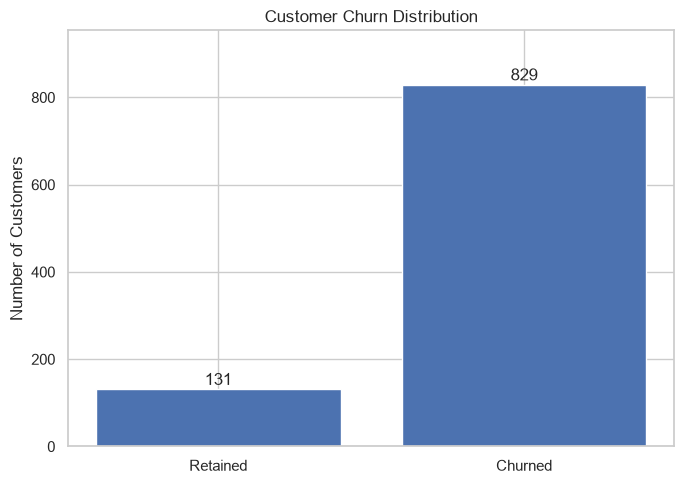

In [15]:
churn_counts = (
    df_eda["churn"]
    .value_counts()
    .reindex([0, 1])
)

labels = ["Retained", "Churned"]

fig, ax = plt.subplots(figsize=(7, 5))

bars = ax.bar(labels, churn_counts.values)

for bar, count in zip(bars, churn_counts.values):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        count + 10,
        str(count),
        ha="center"
    )

ax.set_title("Customer Churn Distribution")
ax.set_ylabel("Number of Customers")
ax.set_ylim(0, churn_counts.max() * 1.15)

plt.tight_layout()
plt.savefig(FIGURES_DIR / "01_churn_distribution.png", dpi=300)
plt.show()

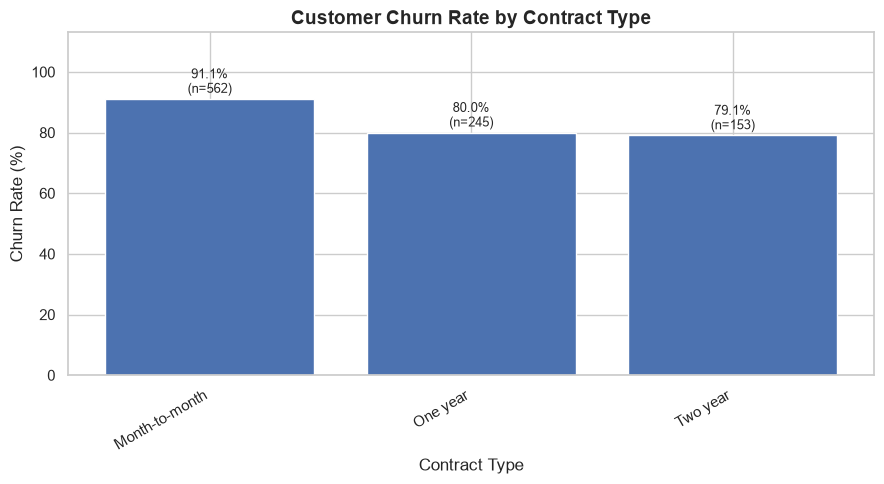

,churn_rate,customer_count
contract_type,,
Month-to-month,91.103203,562
One year,80.000000,245
Two year,79.084967,153


In [16]:
contract_summary = plot_churn_rate(
    column="contract_type",
    title="Customer Churn Rate by Contract Type",
    filename="02_contract_churn.png",
    order=["Month-to-month", "One year", "Two year"]
)

display(contract_summary)

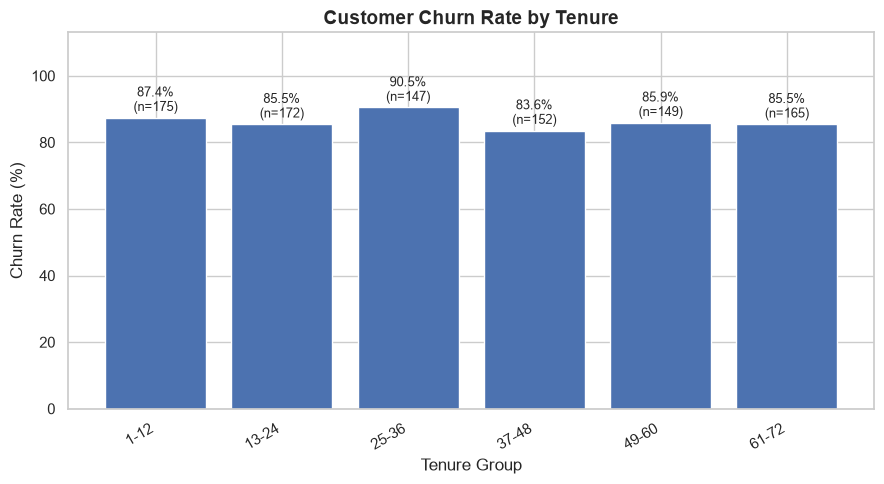

,churn_rate,customer_count
tenure_group,,
1-12,87.428571,175
13-24,85.465116,172
25-36,90.476190,147
37-48,83.552632,152
49-60,85.906040,149
61-72,85.454545,165


In [17]:
df_eda["tenure_group"] = pd.cut(
    df_eda["tenure_months"],
    bins=[0, 12, 24, 36, 48, 60, 72],
    labels=[
        "1-12",
        "13-24",
        "25-36",
        "37-48",
        "49-60",
        "61-72"
    ],
    include_lowest=True
)

tenure_summary = plot_churn_rate(
    column="tenure_group",
    title="Customer Churn Rate by Tenure",
    filename="03_tenure_churn.png"
)

display(tenure_summary)

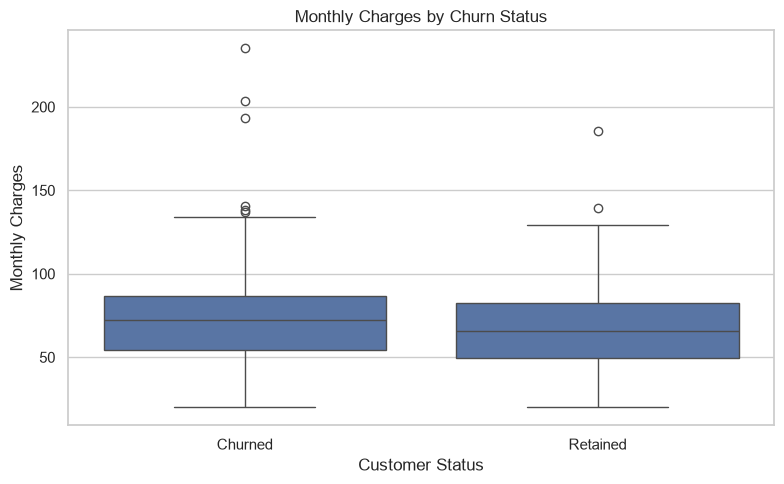

In [18]:
df_eda["churn_label"] = df_eda["churn"].map({
    0: "Retained",
    1: "Churned"
})

plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df_eda,
    x="churn_label",
    y="monthly_charges"
)

plt.title("Monthly Charges by Churn Status")
plt.xlabel("Customer Status")
plt.ylabel("Monthly Charges")

plt.tight_layout()
plt.savefig(
    FIGURES_DIR / "04_monthly_charges.png",
    dpi=300
)
plt.show()

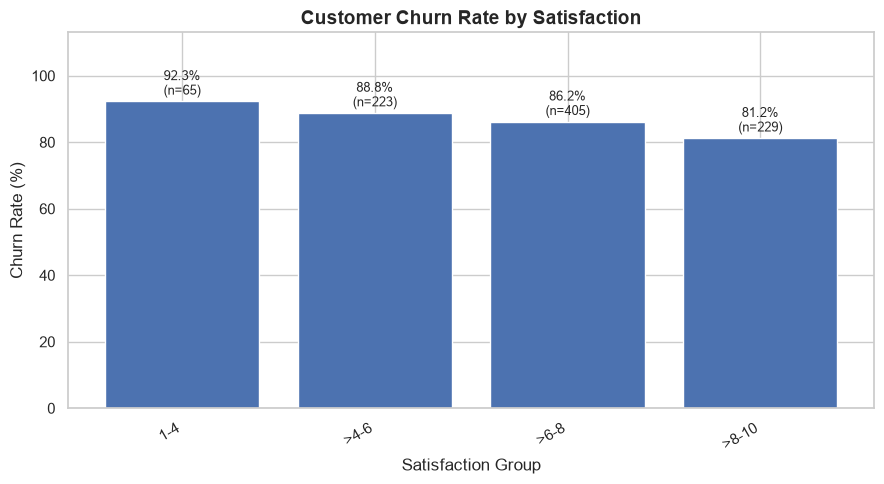

,churn_rate,customer_count
satisfaction_group,,
1-4,92.307692,65
>4-6,88.789238,223
>6-8,86.172840,405
>8-10,81.222707,229


In [19]:
df_eda["satisfaction_group"] = pd.cut(
    df_eda["satisfaction_score"],
    bins=[0, 4, 6, 8, 10],
    labels=[
        "1-4",
        ">4-6",
        ">6-8",
        ">8-10"
    ],
    include_lowest=True
)

satisfaction_summary = plot_churn_rate(
    column="satisfaction_group",
    title="Customer Churn Rate by Satisfaction",
    filename="05_satisfaction_churn.png"
)

display(satisfaction_summary)

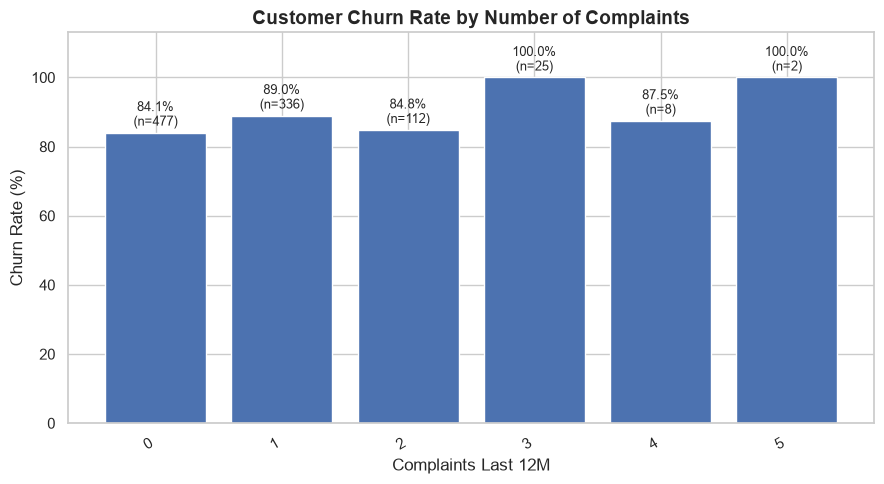

,churn_rate,customer_count
complaints_last_12m,,
0,84.067086,477
1,88.988095,336
2,84.821429,112
3,100.000000,25
4,87.500000,8
5,100.000000,2


In [20]:
complaint_summary = plot_churn_rate(
    column="complaints_last_12m",
    title="Customer Churn Rate by Number of Complaints",
    filename="06_complaints_churn.png"
)

display(complaint_summary)

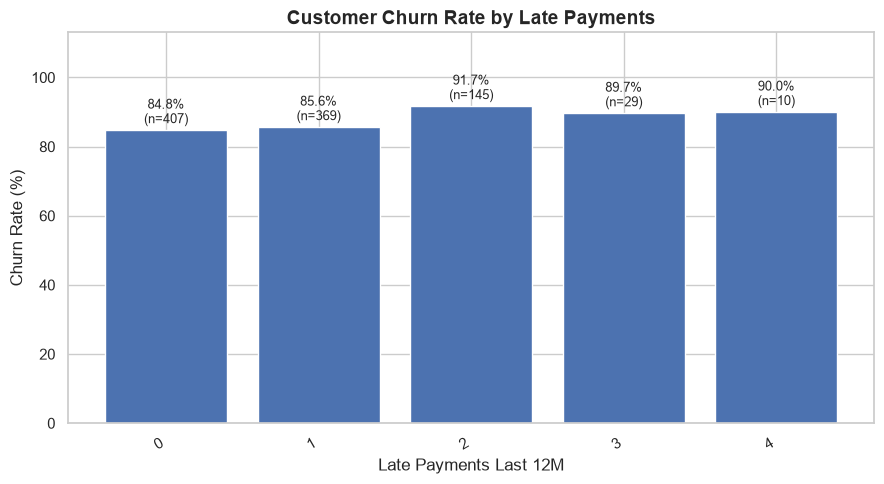

,churn_rate,customer_count
late_payments_last_12m,,
0,84.766585,407
1,85.636856,369
2,91.724138,145
3,89.655172,29
4,90.000000,10


In [21]:
payment_delay_summary = plot_churn_rate(
    column="late_payments_last_12m",
    title="Customer Churn Rate by Late Payments",
    filename="07_late_payments_churn.png"
)

display(payment_delay_summary)

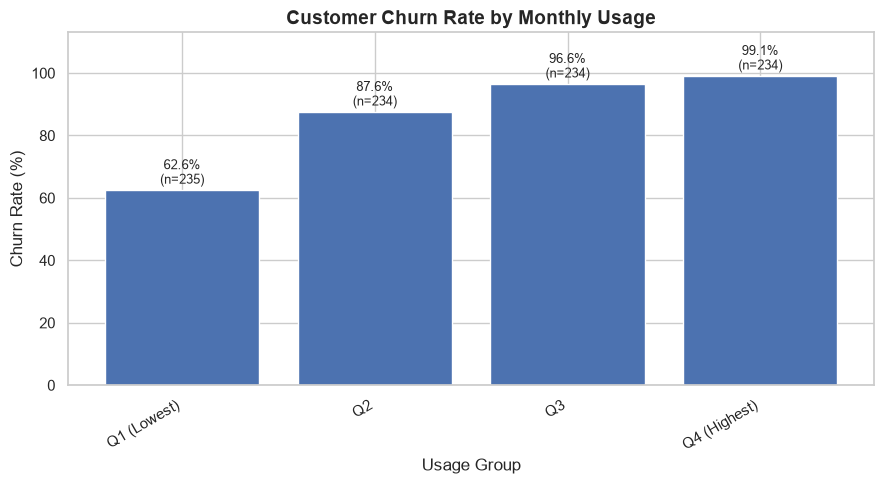

,churn_rate,customer_count
usage_group,,
Q1 (Lowest),62.553191,235
Q2,87.606838,234
Q3,96.581197,234
Q4 (Highest),99.145299,234


In [22]:
df_eda["usage_group"] = pd.qcut(
    df_eda["monthly_usage_gb"],
    q=4,
    labels=[
        "Q1 (Lowest)",
        "Q2",
        "Q3",
        "Q4 (Highest)"
    ]
)

usage_summary = plot_churn_rate(
    column="usage_group",
    title="Customer Churn Rate by Monthly Usage",
    filename="08_usage_churn.png"
)

display(usage_summary)

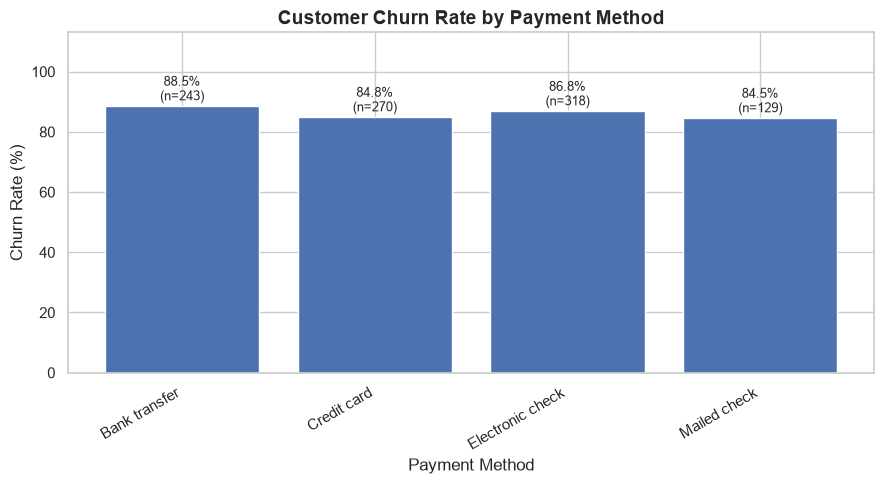

,churn_rate,customer_count
payment_method,,
Bank transfer,88.477366,243
Credit card,84.814815,270
Electronic check,86.792453,318
Mailed check,84.496124,129


In [23]:
payment_summary = plot_churn_rate(
    column="payment_method",
    title="Customer Churn Rate by Payment Method",
    filename="09_payment_method_churn.png"
)

display(payment_summary)

### 2.1 Exploratory Data Analysis Findings

Nine visualizations were created to investigate customer churn patterns using training data only.

#### Key Findings

**1. Target Distribution**

The dataset is highly imbalanced, with approximately 86.4% of training customers belonging to the churned class. This indicates that class-aware evaluation metrics are essential.

**2. Contract Type**

Month-to-month customers demonstrate higher observed churn rates than customers with annual or two-year contracts.

**3. Customer Tenure**

Churn varies across tenure groups, suggesting a potentially nonlinear relationship between customer tenure and churn.

**4. Monthly Charges**

Churned customers generally have higher median monthly charges than retained customers, although the distributions overlap.

**5. Satisfaction**

Lower customer satisfaction is associated with increased churn rates.

**6. Complaints**

Customers with frequent complaints may have higher churn risk. However, categories with very few observations require cautious interpretation.

**7. Late Payments**

Customers with multiple late payments generally demonstrate increased churn rates.

**8. Monthly Usage**

Monthly internet usage exhibits a strong positive association with churn, especially among customers in higher usage quartiles.

**9. Payment Method**

Churn rates vary across payment methods, although the differences are relatively modest.

#### Preliminary Conclusion

Contract type, satisfaction, late payment history, monthly charges, and internet usage appear relevant for churn prediction.

These findings are exploratory associations and do not establish causation. Further investigation is needed to identify nonlinear interactions, verify feature availability before the prediction date, and assess predictive performance using cross-validation.

The final test dataset has not been used for exploratory analysis.

## 3. Advanced Exploratory Data Analysis

### Objectives

This section extends the initial exploratory analysis by investigating:

1. Interactions between customer characteristics.
2. Nonlinear relationships between numerical features and churn.
3. Unusual observations and potential data inconsistencies.
4. Potential data leakage and feature availability.

All analyses use training data only. The final test set remains untouched.

,contract_type,satisfaction_band,churn_rate,count
0,Month-to-month,Low (1-4),97.06,34
1,Month-to-month,Medium (>4-7),94.23,260
2,Month-to-month,High (>7-10),86.12,245
3,One year,Low (1-4),94.74,19
4,One year,Medium (>4-7),80.73,109
5,One year,High (>7-10),76.64,107
6,Two year,Low (1-4),75.00,12
7,Two year,Medium (>4-7),80.60,67
8,Two year,High (>7-10),76.81,69


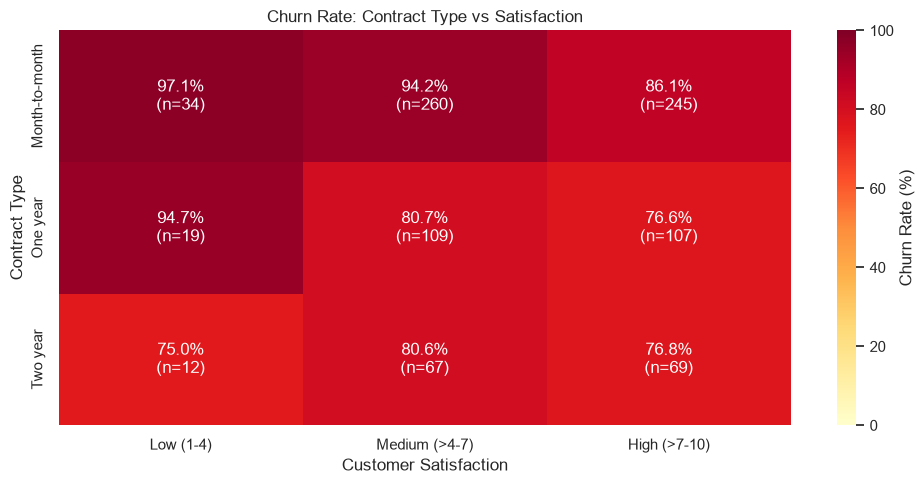

In [24]:
# ==========================================
# 3.1 Contract Type × Satisfaction
# ==========================================

interaction_df = df_train.copy()

interaction_df["satisfaction_band"] = pd.cut(
    interaction_df["satisfaction_score"],
    bins=[0, 4, 7, 10],
    labels=[
        "Low (1-4)",
        "Medium (>4-7)",
        "High (>7-10)"
    ],
    include_lowest=True
)

interaction_summary = (
    interaction_df.groupby(
        ["contract_type", "satisfaction_band"],
        observed=True
    )["churn"]
    .agg(churn_rate="mean", count="size")
    .reset_index()
)

interaction_summary["churn_rate"] *= 100

display(interaction_summary.round(2))

# Prepare heatmap
rates = interaction_summary.pivot(
    index="contract_type",
    columns="satisfaction_band",
    values="churn_rate"
)

counts = interaction_summary.pivot(
    index="contract_type",
    columns="satisfaction_band",
    values="count"
)

annotations = rates.copy().astype(object)

for row in rates.index:
    for col in rates.columns:
        annotations.loc[row, col] = (
            f"{rates.loc[row, col]:.1f}%\n"
            f"(n={int(counts.loc[row, col])})"
        )

plt.figure(figsize=(10, 5))

sns.heatmap(
    rates,
    annot=annotations,
    fmt="",
    cmap="YlOrRd",
    vmin=0,
    vmax=100,
    cbar_kws={"label": "Churn Rate (%)"}
)

plt.title("Churn Rate: Contract Type vs Satisfaction")
plt.xlabel("Customer Satisfaction")
plt.ylabel("Contract Type")

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "10_contract_satisfaction_interaction.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

,contract_type,late_payment_group,churn_rate,count
0,Month-to-month,0 payments,92.80,236
1,Month-to-month,1 payment,88.18,220
2,Month-to-month,2+ payments,93.40,106
3,One year,0 payments,73.58,106
4,One year,1 payment,83.87,93
5,One year,2+ payments,86.96,46
6,Two year,0 payments,73.85,65
7,Two year,1 payment,78.57,56
8,Two year,2+ payments,90.62,32


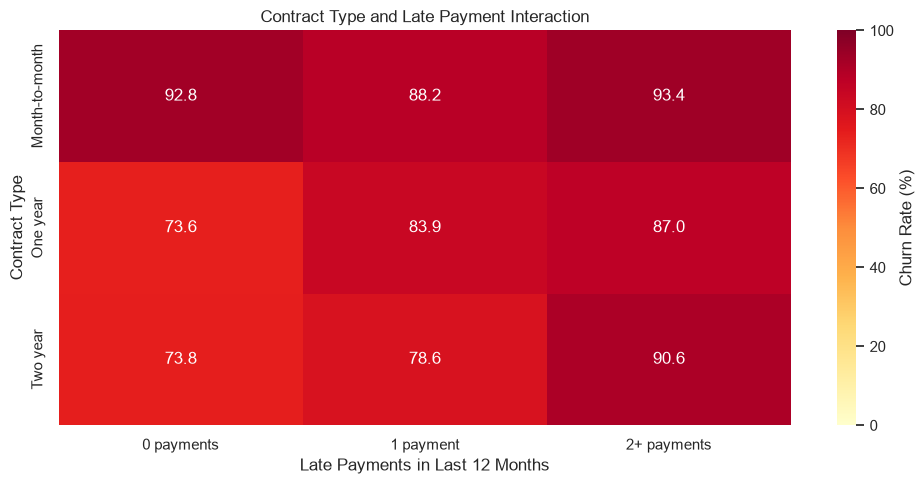

In [25]:
# ==========================================
# 3.2 Contract Type × Late Payments
# ==========================================

payment_interaction = df_train.copy()

payment_interaction["late_payment_group"] = pd.cut(
    payment_interaction["late_payments_last_12m"],
    bins=[-1, 0, 1, float("inf")],
    labels=["0 payments", "1 payment", "2+ payments"]
)

payment_summary = (
    payment_interaction.groupby(
        ["contract_type", "late_payment_group"],
        observed=True
    )["churn"]
    .agg(churn_rate="mean", count="size")
    .reset_index()
)

payment_summary["churn_rate"] *= 100

display(payment_summary.round(2))

payment_rates = payment_summary.pivot(
    index="contract_type",
    columns="late_payment_group",
    values="churn_rate"
)

plt.figure(figsize=(10, 5))

sns.heatmap(
    payment_rates,
    annot=True,
    fmt=".1f",
    cmap="YlOrRd",
    vmin=0,
    vmax=100,
    cbar_kws={"label": "Churn Rate (%)"}
)

plt.title("Contract Type and Late Payment Interaction")
plt.xlabel("Late Payments in Last 12 Months")
plt.ylabel("Contract Type")

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "11_contract_late_payment_interaction.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

,usage_decile,churn_rate,count,decile_label
0,"(1.999, 19.92]",51.06,94,D1
1,"(19.92, 36.02]",63.83,94,D2
2,"(36.02, 44.88]",82.80,93,D3
3,"(44.88, 56.4]",82.11,95,D4
4,"(56.4, 65.0]",95.70,93,D5
5,"(65.0, 73.5]",91.58,95,D6
6,"(73.5, 83.22]",100.00,92,D7
7,"(83.22, 92.8]",98.94,94,D8
8,"(92.8, 111.4]",100.00,94,D9
9,"(111.4, 451.3]",98.92,93,D10


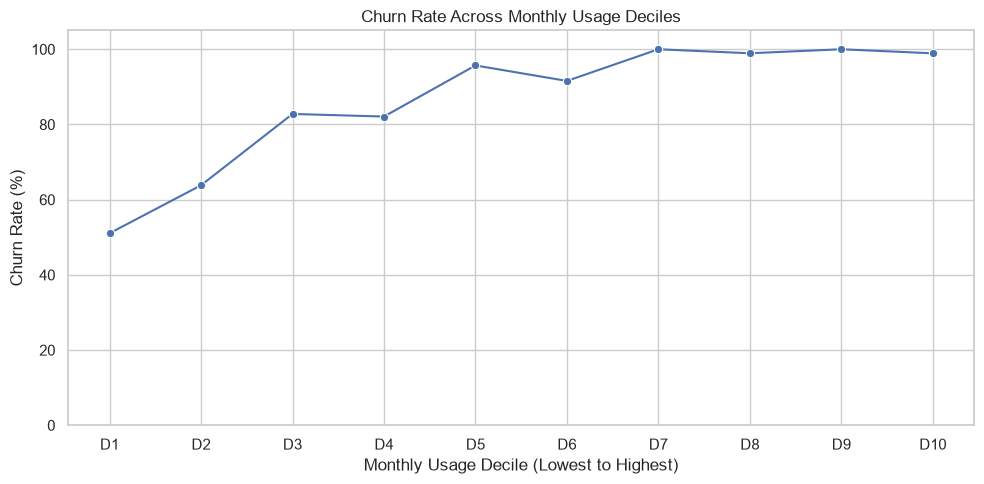

In [26]:
# ==========================================
# 3.3 Nonlinear Monthly Usage Analysis
# ==========================================

usage_df = df_train.dropna(
    subset=["monthly_usage_gb"]
).copy()

usage_df["usage_decile"] = pd.qcut(
    usage_df["monthly_usage_gb"],
    q=10,
    duplicates="drop"
)

usage_summary = (
    usage_df.groupby(
        "usage_decile",
        observed=True
    )["churn"]
    .agg(churn_rate="mean", count="size")
    .reset_index()
)

usage_summary["churn_rate"] *= 100

usage_summary["decile_label"] = [
    f"D{i+1}" for i in range(len(usage_summary))
]

display(usage_summary.round(2))

plt.figure(figsize=(10, 5))

sns.lineplot(
    data=usage_summary,
    x="decile_label",
    y="churn_rate",
    marker="o"
)

plt.title("Churn Rate Across Monthly Usage Deciles")
plt.xlabel("Monthly Usage Decile (Lowest to Highest)")
plt.ylabel("Churn Rate (%)")
plt.ylim(0, 105)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "12_usage_decile_analysis.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [27]:
# ==========================================
# 3.4 Unusual Observations
# ==========================================

# Check customers with no internet service
no_internet_usage = df_train[
    (df_train["internet_service"] == "No") &
    (df_train["monthly_usage_gb"] > 0)
]

print("Customers with 'No' internet service")
print("but positive monthly usage:", len(no_internet_usage))

display(
    no_internet_usage[
        [
            "customer_id",
            "internet_service",
            "monthly_usage_gb"
        ]
    ].head(10)
)

# Review very high internet usage
print("\nTop 5 monthly usage values:")

display(
    df_train.nlargest(
        5, "monthly_usage_gb"
    )[
        [
            "customer_id",
            "internet_service",
            "monthly_usage_gb",
            "churn"
        ]
    ]
)

Customers with 'No' internet service
but positive monthly usage: 122


,customer_id,internet_service,monthly_usage_gb
492,CUST100493,No,73.0
398,CUST100399,No,58.0
614,CUST100615,No,37.2
665,CUST100666,No,69.0
1116,CUST101117,No,77.4
750,CUST100751,No,139.3
711,CUST100712,No,86.0
449,CUST100450,No,72.8
857,CUST100858,No,71.3
466,CUST100467,No,2.0



Top 5 monthly usage values:


,customer_id,internet_service,monthly_usage_gb,churn
684,CUST100685,DSL,451.3,1
587,CUST100588,DSL,443.3,1
424,CUST100425,Fiber optic,353.3,1
282,CUST100283,Fiber optic,169.8,1
853,CUST100854,No,150.2,1


In [28]:
# ==========================================
# 3.5 Billing Consistency Investigation
# ==========================================

billing = df_train.dropna(
    subset=["monthly_charges", "total_charges"]
).copy()

billing["estimated_total"] = (
    billing["monthly_charges"] *
    billing["tenure_months"]
)

billing["relative_difference"] = (
    (billing["total_charges"] - billing["estimated_total"])
    / billing["estimated_total"]
)

unusual_billing = billing[
    billing["relative_difference"].abs() > 0.25
]

print("Records checked:", len(billing))
print("Records with >25% difference:", len(unusual_billing))

display(
    unusual_billing[
        [
            "customer_id",
            "tenure_months",
            "monthly_charges",
            "total_charges",
            "estimated_total",
            "relative_difference"
        ]
    ].round(2)
)

Records checked: 913
Records with >25% difference: 4


,customer_id,tenure_months,monthly_charges,total_charges,estimated_total,relative_difference
635,CUST100636,10,235.01,567.41,2350.1,-0.76
604,CUST100605,10,193.06,473.68,1930.6,-0.75
650,CUST100651,6,203.65,439.24,1221.9,-0.64
22,CUST100023,70,185.81,4627.17,13006.7,-0.64


### 3.6 Data Leakage Assessment

Potential sources of data leakage were reviewed before feature engineering and model training.

The customer_id column will be excluded because it is an identifier rather than a meaningful predictive variable.

The total_charges variable requires particular attention because cumulative charges may include information that would not have been available at the intended prediction date.

Similarly, satisfaction scores, complaint counts, late-payment history, and monthly usage must represent information recorded before the churn prediction point.

The provided dataset does not include a full temporal data dictionary. Therefore, feature availability before the prediction date is treated as a modeling assumption rather than a verified fact.

To reduce leakage risk:
- Customer identifiers will not be used as model features.
- Feature engineering will not use the target variable.
- Learned preprocessing transformations will be fitted on training data only.
- Cross-validation will be used for model development.
- The final test set will remain untouched until final evaluation.
- A sensitivity analysis will assess the influence of potentially problematic features, especially total_charges.

### 3.7 Advanced EDA Findings and Decisions

**Feature Interactions**

Joint analysis of contract type and satisfaction revealed that the association between satisfaction and churn differs across contract categories.

Contract type and late-payment history also demonstrate potentially useful interaction patterns.

**Nonlinear Relationships**

Monthly usage deciles were analyzed to investigate nonlinear relationships between internet usage and churn.

These results motivate comparing linear and tree-based machine learning models.

**Unusual Observations**

A total of 122 training records show positive internet usage despite having internet_service recorded as No.

Four training records also show substantial differences between observed total charges and a simplified monthly charge multiplied by tenure estimate.

These observations are retained because the available data does not establish that they are incorrect.

**Leakage Prevention**

The customer_id field will be excluded from predictive modeling.

Other variables will be assessed based on whether their information would have been available at prediction time.

**Conclusion**

The advanced analysis identified potentially useful feature interactions, nonlinear behavior, and data-quality concerns.

These findings will guide feature engineering, preprocessing, model selection, and sensitivity analysis.

## 4. Feature Engineering

### Objective

Feature engineering transforms existing customer information into additional variables that may improve churn prediction.

Eight new features are constructed using business reasoning and patterns identified during exploratory analysis.

The transformations are implemented in a custom Scikit-learn-compatible transformer, allowing consistent application during cross-validation and future predictions.

No engineered feature directly uses the churn target.

All feature transformations are performed after separating the training and test datasets.

In [29]:
# ==========================================
# 4.1 Import Custom Feature Engineer
# ==========================================

import sys

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.feature_engineering import ChurnFeatureEngineer

print("Feature engineering module imported successfully!")

Feature engineering module imported successfully!


In [30]:
# ==========================================
# 4.2 Separate Features and Target
# ==========================================

# Exclude identifier, target and potentially
# leakage-prone cumulative charges.

DROP_COLUMNS = [
    "customer_id",
    "churn",
    "total_charges"
]

X_train = df_train.drop(
    columns=DROP_COLUMNS
).copy()

y_train = df_train["churn"].copy()

print("Training features:", X_train.shape)
print("Training target:", y_train.shape)

print("\nInput feature columns:")
print(X_train.columns.tolist())

Training features: (960, 17)
Training target: (960,)

Input feature columns:
['age', 'tenure_months', 'contract_type', 'internet_service', 'region', 'monthly_charges', 'payment_method', 'paperless_billing', 'dependents', 'support_plan', 'tech_support', 'complaints_last_12m', 'late_payments_last_12m', 'satisfaction_score', 'monthly_usage_gb', 'discount_pct', 'senior_citizen']


In [31]:
# ==========================================
# 4.3 Apply Feature Engineering
# ==========================================

feature_engineer = ChurnFeatureEngineer()

X_train_fe = feature_engineer.fit_transform(
    X_train
)

print("Original training shape:", X_train.shape)
print("Engineered training shape:", X_train_fe.shape)

print(
    "\nNumber of new features:",
    X_train_fe.shape[1] - X_train.shape[1]
)

display(X_train_fe.head())

Original training shape: (960, 17)
Engineered training shape: (960, 25)

Number of new features: 8


,age,tenure_months,contract_type,internet_service,region,monthly_charges,payment_method,paperless_billing,dependents,support_plan,tech_support,complaints_last_12m,late_payments_last_12m,satisfaction_score,monthly_usage_gb,discount_pct,senior_citizen,tenure_years,payment_risk_flag,complaint_intensity,total_service_issues,monthly_charge_per_gb,month_to_month_late_payments,low_satisfaction_flag,charge_satisfaction_interaction
492,61,48,One year,No,Western,81.32,Credit card,No,No,No,No,0,2,5.3,73.0,6.50,1,4.000000,1,0.000000,2,1.098919,0,0.0,38.2204
398,34,61,Two year,No,North Western,52.40,Electronic check,No,No,No,Yes,2,2,4.6,58.0,0.00,0,5.083333,1,0.166667,4,0.888136,0,0.0,28.2960
79,56,63,Month-to-month,DSL,Southern,59.26,Credit card,Yes,Yes,Yes,Yes,1,0,7.3,106.6,0.00,0,5.250000,0,0.083333,1,0.550743,0,0.0,16.0002
614,57,64,Month-to-month,No,Southern,45.09,Electronic check,Yes,No,No,No,1,1,8.2,37.2,22.38,0,5.333333,0,0.083333,2,1.180366,1,0.0,8.1162
527,26,42,Month-to-month,DSL,North Western,34.26,Credit card,No,No,No,No,0,0,5.2,63.7,21.99,1,3.500000,0,0.000000,0,0.529521,0,0.0,16.4448


In [32]:
# ==========================================
# 4.4 Inspect Engineered Features
# ==========================================

engineered_features = [
    "tenure_years",
    "payment_risk_flag",
    "complaint_intensity",
    "total_service_issues",
    "monthly_charge_per_gb",
    "month_to_month_late_payments",
    "low_satisfaction_flag",
    "charge_satisfaction_interaction"
]

display(
    X_train_fe[engineered_features].head(10)
)

print("\nEngineered feature summary:")

display(
    X_train_fe[engineered_features]
    .describe()
    .round(2)
)

,tenure_years,payment_risk_flag,complaint_intensity,total_service_issues,monthly_charge_per_gb,month_to_month_late_payments,low_satisfaction_flag,charge_satisfaction_interaction
492,4.000000,1,0.000000,2,1.098919,0,0.0,38.2204
398,5.083333,1,0.166667,4,0.888136,0,0.0,28.2960
79,5.250000,0,0.083333,1,0.550743,0,0.0,16.0002
614,5.333333,0,0.083333,2,1.180366,1,0.0,8.1162
527,3.500000,0,0.000000,0,0.529521,0,0.0,16.4448
698,4.500000,0,0.083333,1,1.983146,0,0.0,52.9500
665,2.500000,0,0.166667,2,0.951000,0,0.0,4.6599
297,4.750000,0,0.000000,1,1.030377,1,1.0,37.6809
843,4.500000,0,0.166667,3,0.903187,0,0.0,21.7632
769,1.000000,0,0.000000,0,2.690339,0,0.0,39.1552



Engineered feature summary:


,tenure_years,payment_risk_flag,complaint_intensity,total_service_issues,monthly_charge_per_gb,month_to_month_late_payments,low_satisfaction_flag,charge_satisfaction_interaction
count,960.00,960.00,960.00,960.00,910.00,960.00,922.00,897.00
mean,2.99,0.19,0.08,1.52,2.39,0.48,0.07,22.60
std,1.76,0.39,0.15,1.26,4.91,0.77,0.26,14.93
min,0.08,0.00,0.00,0.00,0.13,0.00,0.00,0.00
25%,1.50,0.00,0.00,1.00,0.73,0.00,0.00,11.58
50%,2.92,0.00,0.08,1.00,1.05,0.00,0.00,21.05
75%,4.50,0.00,0.08,2.00,1.70,1.00,0.00,31.34
max,6.00,1.00,2.00,8.00,40.09,4.00,1.00,119.86


In [33]:
# ==========================================
# 4.5 Feature Engineering Validation
# ==========================================

# Check target and identifier exclusion
assert "churn" not in X_train_fe.columns
assert "customer_id" not in X_train_fe.columns
assert "total_charges" not in X_train_fe.columns

# Check all engineered features exist
assert all(
    feature in X_train_fe.columns
    for feature in engineered_features
)

# Check all customers are preserved
assert len(X_train_fe) == len(X_train)

# Check original data was not modified
assert all(
    col not in X_train.columns
    for col in engineered_features
)

# Check we created exactly eight features
assert len(engineered_features) == 8

print("All feature engineering validation checks passed!")

All feature engineering validation checks passed!


### 4.6 Feature Engineering Rationale

Eight features were engineered to represent customer relationship duration, payment behavior, service problems, customer satisfaction, and interactions between existing attributes.

**1. Tenure Years**

Customer tenure was converted from months into years to improve interpretability.

**2. Payment Risk Flag**

Customers with two or more late payments were assigned a payment-risk indicator of 1. This threshold represents a business-defined payment concern rather than a threshold optimized using the target.

**3. Complaint Intensity**

The number of complaints was divided by the customer's available observation months, capped at 12 months. This provides an approximate complaint frequency that accounts for shorter customer relationships.

**4. Total Service Issues**

Complaints and late payments were combined to represent the overall frequency of recorded customer service and payment problems.

**5. Monthly Charge-to-Usage Ratio**

Monthly charges were divided by monthly usage plus one. Adding one stabilizes the calculation when usage is close to zero and avoids division by zero. This is a smoothed ratio, not an exact price per gigabyte.

**6. Month-to-Month Late Payments**

An interaction variable was created to represent late-payment history specifically for customers using month-to-month contracts.

**7. Low Satisfaction Flag**

Customers with satisfaction scores of 4 or below were flagged. Missing satisfaction values were preserved for subsequent imputation.

**8. Charge-Satisfaction Interaction**

Monthly charges were combined with an inverse satisfaction score to represent the interaction between customer charges and dissatisfaction.

### Leakage Prevention

All engineered variables are calculated using input customer attributes without directly using the churn label.

Customer identifiers and total_charges were excluded from the baseline predictive feature set.

Feature engineering is implemented using a reusable Scikit-learn transformer that can be included in the model pipeline.

The transformer does not learn statistics from the full dataset. Subsequent preprocessing steps, including imputation and scaling, will be fitted within training folds.

Feature availability before the prediction date remains an explicit assumption because the dataset does not include complete temporal information.

### Conclusion

Eight engineered features were successfully added to the training dataset, increasing the number of predictive features from 17 to 25.

Their effectiveness will be evaluated using cross-validation and comparisons with baseline models.

## 5. Data Preprocessing Pipeline

### Objective

This section implements a reproducible preprocessing pipeline using Scikit-learn's Pipeline and ColumnTransformer.

The pipeline performs:

1. Feature engineering
2. Numerical missing-value imputation using the median
3. Missing-value indicator generation
4. Numerical feature standardization
5. Categorical missing-value imputation
6. One-hot encoding of categorical variables

The preprocessing pipeline will be fitted independently within each cross-validation training fold during model development to prevent data leakage.

The final test set will remain untouched until final evaluation.

In [34]:
# ==========================================
# 5.1 Import Preprocessing Pipeline
# ==========================================

from src.preprocessing import (
    build_preprocessor,
    build_preprocessing_pipeline
)

print("Preprocessing module imported successfully!")

Preprocessing module imported successfully!


In [35]:
# ==========================================
# 5.2 Build and Test Preprocessing Pipeline
# ==========================================

preprocessing_pipeline = build_preprocessing_pipeline()

X_train_processed = preprocessing_pipeline.fit_transform(
    X_train
)

print("Original training shape:", X_train.shape)

print(
    "Processed training shape:",
    X_train_processed.shape
)

print(
    "Missing values after preprocessing:",
    np.isnan(X_train_processed).sum()
)

Original training shape: (960, 17)
Processed training shape: (960, 50)
Missing values after preprocessing: 0


In [36]:
# ==========================================
# 5.3 Inspect Processed Features
# ==========================================

feature_names = (
    preprocessing_pipeline
    .named_steps["preprocessor"]
    .get_feature_names_out()
)

processed_df = pd.DataFrame(
    X_train_processed,
    columns=feature_names,
    index=X_train.index
)

print("Number of processed columns:", len(feature_names))

display(processed_df.head())

Number of processed columns: 50


,num__age,num__tenure_months,num__monthly_charges,num__complaints_last_12m,num__late_payments_last_12m,num__satisfaction_score,num__monthly_usage_gb,num__discount_pct,num__senior_citizen,num__tenure_years,num__payment_risk_flag,num__complaint_intensity,num__total_service_issues,num__monthly_charge_per_gb,num__month_to_month_late_payments,num__low_satisfaction_flag,num__charge_satisfaction_interaction,num__missingindicator_monthly_charges,num__missingindicator_satisfaction_score,num__missingindicator_monthly_usage_gb,num__missingindicator_monthly_charge_per_gb,num__missingindicator_low_satisfaction_flag,num__missingindicator_charge_satisfaction_interaction,cat__contract_type_Month-to-month,cat__contract_type_One year,cat__contract_type_Two year,cat__internet_service_DSL,cat__internet_service_Fiber optic,cat__internet_service_No,cat__region_Central,cat__region_Eastern,cat__region_North Central,cat__region_North Western,cat__region_Northern,cat__region_Sabaragamuwa,cat__region_Southern,cat__region_Uva,cat__region_Western,cat__payment_method_Bank transfer,cat__payment_method_Credit card,cat__payment_method_Electronic check,cat__payment_method_Mailed check,cat__paperless_billing_No,cat__paperless_billing_Yes,cat__dependents_No,cat__dependents_Yes,cat__support_plan_No,cat__support_plan_Yes,cat__tech_support_No,cat__tech_support_Yes
492,0.857470,0.574694,0.416827,-0.820265,1.357910,-0.876271,0.183799,-0.395659,2.171241,0.574694,2.053629,-0.505777,0.377643,-0.255513,-0.619903,-0.269492,1.089794,-0.173329,-0.203014,-0.156673,-0.234404,-0.203014,-0.265017,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0
398,-0.760351,1.190120,-0.741689,1.506041,1.357910,-1.284488,-0.207818,-1.368557,-0.460566,1.190120,2.053629,0.571602,1.964241,-0.299551,-0.619903,-0.269492,0.401878,-0.173329,-0.203014,-0.156673,-0.234404,-0.203014,-0.265017,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0
79,0.557874,1.284801,-0.466882,0.342888,-0.941197,0.290065,1.061023,-1.368557,-0.460566,1.284801,-0.486943,0.032913,-0.415655,-0.370043,-0.619903,-0.269492,-0.450414,-0.173329,-0.203014,-0.156673,-0.234404,-0.203014,-0.265017,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0
614,0.617793,1.332141,-1.034522,0.342888,0.208356,0.814917,-0.750862,1.981205,-0.460566,1.332141,-0.486943,0.032913,0.377643,-0.238496,0.673808,-0.269492,-0.996898,-0.173329,-0.203014,-0.156673,-0.234404,-0.203014,-0.265017,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,1.0,0.0,1.0,0.0
527,-1.239705,0.290651,-1.468365,-0.820265,-0.941197,-0.934588,-0.059004,1.922832,2.171241,0.290651,-0.486943,-0.505777,-1.208954,-0.374477,-0.619903,-0.269492,-0.419596,-0.173329,-0.203014,-0.156673,-0.234404,-0.203014,-0.265017,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0


In [37]:
# ==========================================
# 5.4 Validate Preprocessing Pipeline
# ==========================================

# Check all training customers are preserved
assert X_train_processed.shape[0] == len(X_train)

# Check that no missing values remain
assert not np.isnan(X_train_processed).any()

# Check every output is finite
assert np.isfinite(X_train_processed).all()

# Check feature names match output columns
assert len(feature_names) == X_train_processed.shape[1]

# Verify excluded columns were not reintroduced
assert not any(
    "customer_id" in name
    or "total_charges" in name
    or "churn" in name
    for name in feature_names
)

print("All preprocessing validation checks passed!")

All preprocessing validation checks passed!


In [38]:
# ==========================================
# 5.5 Demonstrate Leakage-Safe Preprocessing
# ==========================================

# Split existing training data for demonstration only
X_demo_train, X_demo_validation = train_test_split(
    X_train,
    test_size=0.20,
    random_state=RANDOM_STATE
)

# Build a fresh pipeline
demo_pipeline = build_preprocessing_pipeline()

# Learn preprocessing parameters only
# from demonstration training customers
demo_pipeline.fit(X_demo_train)

# Apply the SAME fitted transformations
# to unseen demonstration validation customers
X_demo_processed = demo_pipeline.transform(
    X_demo_validation
)

print(
    "Demo training customers:",
    len(X_demo_train)
)

print(
    "Demo validation customers:",
    len(X_demo_validation)
)

print(
    "Processed validation shape:",
    X_demo_processed.shape
)

print(
    "Validation missing values:",
    np.isnan(X_demo_processed).sum()
)

Demo training customers: 768
Demo validation customers: 192
Processed validation shape: (192, 50)
Validation missing values: 0


### 5.6 Preprocessing Strategy and Leakage Prevention

A reusable preprocessing pipeline was developed using Scikit-learn's Pipeline and ColumnTransformer.

#### Numerical Preprocessing

Missing numerical values are replaced using median imputation. Missing-value indicators are added to preserve information about missingness.

Numerical features are standardized using StandardScaler to ensure comparable feature scales.

#### Categorical Preprocessing

Missing categorical values are handled using most-frequent imputation.

Categorical variables are converted into numerical representations using OneHotEncoder.

Unknown categories encountered during prediction are handled without raising errors.

#### Feature Engineering Integration

The custom ChurnFeatureEngineer transformer is included as the first pipeline step.

This ensures the same feature engineering rules are applied consistently during training, cross-validation, and inference.

#### Leakage Prevention

The final test dataset remains untouched.

All learned preprocessing operations will be fitted inside the model-training and cross-validation pipelines.

The complete training set was used for an initial preprocessing demonstration only. The resulting transformed matrix will not be used for cross-validation or hyperparameter tuning.

Customer identifiers, target labels, and the potentially leakage-prone total_charges field are excluded from the baseline predictive feature set.

#### Validation

The pipeline successfully transforms customer records into numerical features without remaining missing or non-finite values.

The preprocessing pipeline is ready to be integrated with machine learning classifiers.

## 6. Machine Learning Model Development

### 6.1 Logistic Regression Baseline

Logistic Regression is used as the first classification model because it provides an interpretable baseline for customer churn prediction.

The classifier is integrated with feature engineering and preprocessing using a Scikit-learn Pipeline.

Model performance is evaluated using stratified 5-fold cross-validation on training data.

The following metrics are considered:

- Accuracy
- Balanced Accuracy
- Precision
- Recall
- F1 Score
- ROC-AUC
- PR-AUC (Average Precision)

A DummyClassifier is also evaluated to provide a majority-class benchmark.

The final held-out test set is not used during this stage.

In [39]:
# ==========================================
# 6.2 Build Logistic Regression Model
# ==========================================

from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier

from sklearn.model_selection import (
    StratifiedKFold,
    cross_validate,
    cross_val_predict
)

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

from src.modeling import build_model_pipeline

# Create Logistic Regression classifier
logistic_classifier = LogisticRegression(
    max_iter=3000,
    random_state=RANDOM_STATE
)

# Build complete pipeline
logistic_pipeline = build_model_pipeline(
    logistic_classifier
)

# Create a simple majority-class baseline
dummy_model = DummyClassifier(
    strategy="most_frequent"
)

print("Logistic Regression pipeline created!")
print(logistic_pipeline)

Logistic Regression pipeline created!
Pipeline(steps=[('feature_engineering', ChurnFeatureEngineer()),
                ('preprocessor',
                 ColumnTransformer(sparse_threshold=0,
                                   transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(add_indicator=True,
                                                                                 strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  <sklearn.compose._column_transformer.make_column_selector object at 0x000001E728C8A840>),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                               

In [40]:
# ==========================================
# 6.3 Stratified Cross-Validation
# ==========================================

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

scoring = {
    "accuracy": "accuracy",
    "balanced_accuracy": "balanced_accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc",
    "pr_auc": "average_precision"
}

# Evaluate Logistic Regression
logistic_cv_results = cross_validate(
    logistic_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=1,
    error_score="raise"
)

# Evaluate majority-class baseline
dummy_cv_results = cross_validate(
    dummy_model,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=1
)

print("Cross-validation completed successfully!")

Cross-validation completed successfully!


In [41]:
# ==========================================
# 6.4 Cross-Validation Results
# ==========================================

comparison = pd.DataFrame({
    "Metric": list(scoring.keys()),

    "Dummy Baseline": [
        dummy_cv_results[f"test_{metric}"].mean()
        for metric in scoring
    ],

    "Logistic Regression": [
        logistic_cv_results[f"test_{metric}"].mean()
        for metric in scoring
    ],

    "Logistic Regression Std": [
        logistic_cv_results[f"test_{metric}"].std()
        for metric in scoring
    ]
})

display(comparison.round(4))

,Metric,Dummy Baseline,Logistic Regression,Logistic Regression Std
0,accuracy,0.8635,0.8833,0.0107
1,balanced_accuracy,0.5000,0.6756,0.0393
2,precision,0.8635,0.9090,0.0115
3,recall,1.0000,0.9614,0.0124
4,f1,0.9268,0.9344,0.0059
5,roc_auc,0.5000,0.8683,0.0462
6,pr_auc,0.8635,0.9722,0.0143


In [42]:
# ==========================================
# 6.5 Out-of-Fold Predictions
# ==========================================

logistic_oof_probabilities = cross_val_predict(
    logistic_pipeline,
    X_train,
    y_train,
    cv=cv,
    method="predict_proba",
    n_jobs=1
)[:, 1]

# Temporary threshold for baseline comparison
BASELINE_THRESHOLD = 0.50

logistic_oof_predictions = (
    logistic_oof_probabilities >= BASELINE_THRESHOLD
).astype(int)

print("OUT-OF-FOLD CLASSIFICATION REPORT")
print("=" * 45)

print(
    classification_report(
        y_train,
        logistic_oof_predictions,
        target_names=["Retained", "Churned"],
        zero_division=0
    )
)

print(
    "Out-of-fold ROC-AUC:",
    round(
        roc_auc_score(
            y_train,
            logistic_oof_probabilities
        ),
        4
    )
)

print(
    "Out-of-fold PR-AUC:",
    round(
        average_precision_score(
            y_train,
            logistic_oof_probabilities
        ),
        4
    )
)

OUT-OF-FOLD CLASSIFICATION REPORT
              precision    recall  f1-score   support

    Retained       0.61      0.39      0.48       131
     Churned       0.91      0.96      0.93       829

    accuracy                           0.88       960
   macro avg       0.76      0.68      0.71       960
weighted avg       0.87      0.88      0.87       960

Out-of-fold ROC-AUC: 0.8646
Out-of-fold PR-AUC: 0.9706


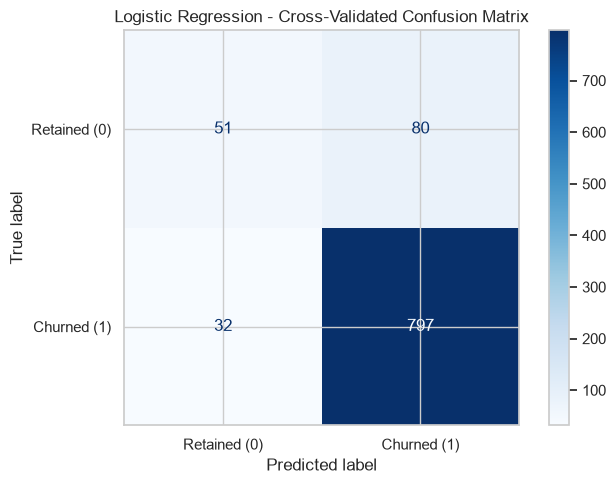

In [43]:
# ==========================================
# 6.6 Confusion Matrix
# ==========================================

fig, ax = plt.subplots(figsize=(7, 5))

ConfusionMatrixDisplay.from_predictions(
    y_train,
    logistic_oof_predictions,
    display_labels=[
        "Retained (0)",
        "Churned (1)"
    ],
    cmap="Blues",
    values_format="d",
    ax=ax
)

ax.set_title(
    "Logistic Regression - Cross-Validated Confusion Matrix"
)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "13_logistic_regression_cv_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### 6.7 Logistic Regression Baseline Evaluation

Logistic Regression was developed as the first machine learning classifier for customer churn prediction.

The model was integrated into a complete Scikit-learn Pipeline containing feature engineering, numerical preprocessing, categorical encoding, and classification.

#### Cross-Validation Strategy

Stratified 5-fold cross-validation was applied to the training dataset containing 960 customer observations.

All learned preprocessing operations were fitted within the corresponding training folds to reduce data leakage.

The final 240-customer test dataset remained untouched.

#### Baseline Comparison

A majority-class DummyClassifier was used as a benchmark.

Because the dataset contains a high proportion of churned customers, a classifier that always predicts churn can achieve high accuracy without meaningfully distinguishing customer risk.

Therefore, accuracy alone is insufficient for evaluating the model.

#### Evaluation Metrics

Model performance was evaluated using accuracy, balanced accuracy, precision, recall, F1 score, ROC-AUC, and PR-AUC.

Cross-validated predictions were also used to generate a confusion matrix.

The initial classification threshold was set to 0.50 for baseline comparison purposes only.

#### Model Limitations

The dataset is highly imbalanced, making class-specific performance important.

High overall accuracy or precision does not necessarily indicate useful identification of the retained minority class.

The probability outputs have not yet been calibrated, and the operating threshold has not been selected according to business constraints.

#### Next Steps

The Logistic Regression baseline will be compared with Random Forest and Gradient Boosting.

Subsequent stages will include hyperparameter tuning, imbalance handling, threshold analysis, calibration, explainability, and retention intervention simulation.

### 6.8 Logistic Regression Results and Interpretation

The Logistic Regression model was evaluated using out-of-fold predictions from stratified 5-fold cross-validation.

**Results:**
- Accuracy: 0.88
- Churn Precision: 0.91
- Churn Recall: 0.96
- Churn F1 Score: 0.93
- Retained Recall: 0.39
- ROC-AUC: 0.8646
- Average Precision (PR-AUC): 0.9706

**Interpretation:**

The model demonstrates useful discrimination between churned and retained customers, achieving a ROC-AUC of 0.8646.

At the default classification threshold of 0.50, the model identifies approximately 96% of actual churners. However, retained-customer recall is only 39%, indicating that many customers who remain are incorrectly classified as churners.

Although overall accuracy reaches approximately 88%, the majority-class baseline already achieves approximately 86.35% accuracy. Therefore, accuracy alone provides limited evidence of model effectiveness.

The average precision of 0.9706 should also be interpreted relative to the high positive-class prevalence of approximately 86.35%.

These findings highlight the importance of risk ranking, threshold optimization, and business-oriented evaluation.

The next stage compares Logistic Regression with Random Forest to investigate whether nonlinear decision boundaries improve predictive performance.

### 6.9 Random Forest Classification

Random Forest is the second classification algorithm evaluated in this project.

It combines multiple decision trees to learn nonlinear relationships and interactions between customer characteristics.

The model uses the same preprocessing pipeline and stratified 5-fold cross-validation strategy as Logistic Regression to ensure a consistent comparison.

The initial model is trained without class weighting or hyperparameter optimization. These techniques will be evaluated in later stages.

The final test dataset remains untouched.

In [44]:
# ==========================================
# 6.10 Build Random Forest Classifier
# ==========================================

from sklearn.ensemble import RandomForestClassifier

random_forest_classifier = RandomForestClassifier(
    n_estimators=200,
    random_state=RANDOM_STATE,
    n_jobs=-1
)

random_forest_pipeline = build_model_pipeline(
    random_forest_classifier
)

print("Random Forest pipeline created successfully!")
print(random_forest_pipeline)

Random Forest pipeline created successfully!
Pipeline(steps=[('feature_engineering', ChurnFeatureEngineer()),
                ('preprocessor',
                 ColumnTransformer(sparse_threshold=0,
                                   transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(add_indicator=True,
                                                                                 strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  <sklearn.compose._column_transformer.make_column_selector object at 0x000001E72824C5F0>),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                        

In [45]:
# ==========================================
# 6.11 Random Forest Cross-Validation
# ==========================================

random_forest_cv_results = cross_validate(
    random_forest_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=1,
    error_score="raise"
)

print("Random Forest cross-validation completed!")

Random Forest cross-validation completed!


In [46]:
# ==========================================
# 6.12 Baseline Model Comparison
# ==========================================

model_results = []

models_to_compare = {
    "Dummy Classifier": dummy_cv_results,
    "Logistic Regression": logistic_cv_results,
    "Random Forest": random_forest_cv_results
}

for model_name, results in models_to_compare.items():

    row = {"Model": model_name}

    for metric in scoring:
        row[metric] = results[
            f"test_{metric}"
        ].mean()

        row[f"{metric}_std"] = results[
            f"test_{metric}"
        ].std()

    model_results.append(row)

baseline_comparison = pd.DataFrame(model_results)

display(
    baseline_comparison[
        [
            "Model",
            "accuracy",
            "balanced_accuracy",
            "precision",
            "recall",
            "f1",
            "roc_auc",
            "pr_auc"
        ]
    ].round(4)
)

,Model,accuracy,balanced_accuracy,precision,recall,f1,roc_auc,pr_auc
0,Dummy Classifier,0.8635,0.5000,0.8635,1.0000,0.9268,0.5000,0.8635
1,Logistic Regression,0.8833,0.6756,0.9090,0.9614,0.9344,0.8683,0.9722
2,Random Forest,0.8802,0.5999,0.8881,0.9855,0.9343,0.8509,0.9658


In [47]:
# ==========================================
# 6.13 Random Forest OOF Predictions
# ==========================================

rf_oof_probabilities = cross_val_predict(
    random_forest_pipeline,
    X_train,
    y_train,
    cv=cv,
    method="predict_proba",
    n_jobs=1
)[:, 1]

rf_oof_predictions = (
    rf_oof_probabilities >= 0.50
).astype(int)

print("RANDOM FOREST CLASSIFICATION REPORT")
print("=" * 45)

print(
    classification_report(
        y_train,
        rf_oof_predictions,
        target_names=["Retained", "Churned"],
        zero_division=0
    )
)

print(
    "Out-of-fold ROC-AUC:",
    round(
        roc_auc_score(
            y_train,
            rf_oof_probabilities
        ),
        4
    )
)

print(
    "Out-of-fold PR-AUC:",
    round(
        average_precision_score(
            y_train,
            rf_oof_probabilities
        ),
        4
    )
)

RANDOM FOREST CLASSIFICATION REPORT
              precision    recall  f1-score   support

    Retained       0.69      0.19      0.30       131
     Churned       0.89      0.99      0.93       829

    accuracy                           0.88       960
   macro avg       0.79      0.59      0.62       960
weighted avg       0.86      0.88      0.85       960

Out-of-fold ROC-AUC: 0.8491
Out-of-fold PR-AUC: 0.9638


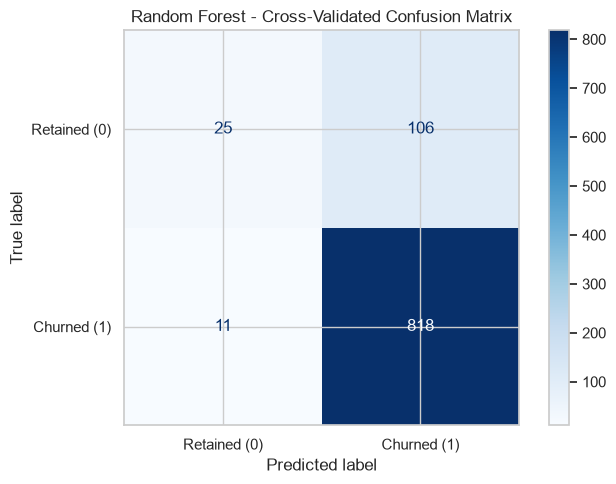

In [48]:
# ==========================================
# 6.14 Random Forest Confusion Matrix
# ==========================================

fig, ax = plt.subplots(figsize=(7, 5))

ConfusionMatrixDisplay.from_predictions(
    y_train,
    rf_oof_predictions,
    display_labels=[
        "Retained (0)",
        "Churned (1)"
    ],
    cmap="Blues",
    values_format="d",
    ax=ax
)

ax.set_title(
    "Random Forest - Cross-Validated Confusion Matrix"
)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "14_random_forest_cv_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### 6.15 Random Forest Baseline Evaluation

A Random Forest classifier was developed as the second machine learning model.

The model was configured with 200 decision trees and a fixed random seed of 42.

The same feature engineering and preprocessing pipeline used for Logistic Regression was applied to ensure consistency.

Stratified 5-fold cross-validation was performed on the training dataset.

Model performance was measured using accuracy, balanced accuracy, precision, recall, F1 score, ROC-AUC, and average precision.

Out-of-fold predictions were generated to evaluate classification performance and construct a confusion matrix.

The Random Forest results will be compared with Logistic Regression and Gradient Boosting before selecting a model for hyperparameter tuning.

No final test observations were used during model development.

### 6.16 Gradient Boosting Classification

Gradient Boosting is the third classification algorithm evaluated in this project.

The algorithm combines multiple decision trees sequentially, where each new tree attempts to improve the predictions of the existing ensemble.

Gradient Boosting can capture nonlinear relationships and interactions between customer characteristics.

The model is integrated into the same feature engineering and preprocessing pipeline used for Logistic Regression and Random Forest.

Stratified 5-fold cross-validation is used to compare the three models consistently.

The initial model uses standard hyperparameters. Optimization and class-imbalance treatments will be investigated in later stages.

The final test dataset remains untouched.

In [49]:
# ==========================================
# 6.17 Build Gradient Boosting Classifier
# ==========================================

from sklearn.ensemble import GradientBoostingClassifier

# Create Gradient Boosting classifier
gradient_boosting_classifier = GradientBoostingClassifier(
    random_state=RANDOM_STATE
)

# Build complete pipeline
gradient_boosting_pipeline = build_model_pipeline(
    gradient_boosting_classifier
)

print("Gradient Boosting pipeline created successfully!")

print(gradient_boosting_pipeline)

Gradient Boosting pipeline created successfully!
Pipeline(steps=[('feature_engineering', ChurnFeatureEngineer()),
                ('preprocessor',
                 ColumnTransformer(sparse_threshold=0,
                                   transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(add_indicator=True,
                                                                                 strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  <sklearn.compose._column_transformer.make_column_selector object at 0x000001E728CD9130>),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                    

In [50]:
# ==========================================
# 6.18 Gradient Boosting Cross-Validation
# ==========================================

gradient_boosting_cv_results = cross_validate(
    gradient_boosting_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=1,
    error_score="raise"
)

print("Gradient Boosting cross-validation completed!")

Gradient Boosting cross-validation completed!


In [51]:
# ==========================================
# 6.19 Compare All Baseline Models
# ==========================================

all_model_results = {
    "Dummy Classifier": dummy_cv_results,
    "Logistic Regression": logistic_cv_results,
    "Random Forest": random_forest_cv_results,
    "Gradient Boosting": gradient_boosting_cv_results
}

comparison_rows = []

for model_name, results in all_model_results.items():

    row = {"Model": model_name}

    for metric in scoring:

        row[metric] = results[
            f"test_{metric}"
        ].mean()

        row[f"{metric}_std"] = results[
            f"test_{metric}"
        ].std()

    comparison_rows.append(row)

full_baseline_comparison = pd.DataFrame(
    comparison_rows
)

display(
    full_baseline_comparison[
        [
            "Model",
            "accuracy",
            "balanced_accuracy",
            "precision",
            "recall",
            "f1",
            "roc_auc",
            "pr_auc"
        ]
    ].round(4)
)

,Model,accuracy,balanced_accuracy,precision,recall,f1,roc_auc,pr_auc
0,Dummy Classifier,0.8635,0.5000,0.8635,1.0000,0.9268,0.5000,0.8635
1,Logistic Regression,0.8833,0.6756,0.9090,0.9614,0.9344,0.8683,0.9722
2,Random Forest,0.8802,0.5999,0.8881,0.9855,0.9343,0.8509,0.9658
3,Gradient Boosting,0.8854,0.6672,0.9063,0.9674,0.9358,0.8745,0.9734


In [52]:
# ==========================================
# 6.20 Gradient Boosting OOF Predictions
# ==========================================

gb_oof_probabilities = cross_val_predict(
    gradient_boosting_pipeline,
    X_train,
    y_train,
    cv=cv,
    method="predict_proba",
    n_jobs=1
)[:, 1]

# Initial classification threshold
gb_oof_predictions = (
    gb_oof_probabilities >= 0.50
).astype(int)

print("GRADIENT BOOSTING CLASSIFICATION REPORT")
print("=" * 50)

print(
    classification_report(
        y_train,
        gb_oof_predictions,
        target_names=["Retained", "Churned"],
        zero_division=0
    )
)

print(
    "Out-of-fold ROC-AUC:",
    round(
        roc_auc_score(
            y_train,
            gb_oof_probabilities
        ),
        4
    )
)

print(
    "Out-of-fold PR-AUC:",
    round(
        average_precision_score(
            y_train,
            gb_oof_probabilities
        ),
        4
    )
)

GRADIENT BOOSTING CLASSIFICATION REPORT
              precision    recall  f1-score   support

    Retained       0.64      0.37      0.47       131
     Churned       0.91      0.97      0.94       829

    accuracy                           0.89       960
   macro avg       0.77      0.67      0.70       960
weighted avg       0.87      0.89      0.87       960

Out-of-fold ROC-AUC: 0.8752
Out-of-fold PR-AUC: 0.9724


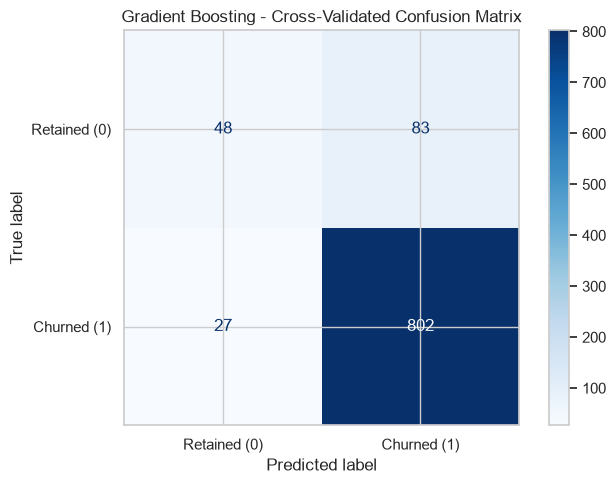

In [53]:
# ==========================================
# 6.21 Gradient Boosting Confusion Matrix
# ==========================================

fig, ax = plt.subplots(figsize=(7, 5))

ConfusionMatrixDisplay.from_predictions(
    y_train,
    gb_oof_predictions,
    display_labels=[
        "Retained (0)",
        "Churned (1)"
    ],
    cmap="Blues",
    values_format="d",
    ax=ax
)

ax.set_title(
    "Gradient Boosting - Cross-Validated Confusion Matrix"
)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "15_gradient_boosting_cv_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

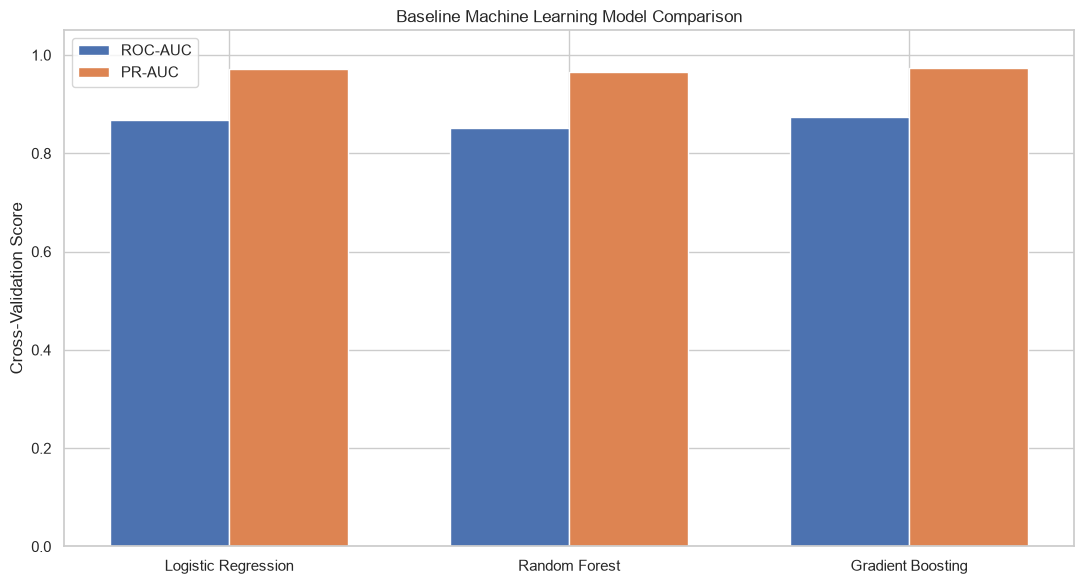

In [54]:
# ==========================================
# 6.22 Baseline Model Comparison Chart
# ==========================================

plot_data = full_baseline_comparison[
    full_baseline_comparison["Model"] != "Dummy Classifier"
].copy()

x = np.arange(len(plot_data))
width = 0.35

fig, ax = plt.subplots(figsize=(11, 6))

ax.bar(
    x - width / 2,
    plot_data["roc_auc"],
    width,
    label="ROC-AUC"
)

ax.bar(
    x + width / 2,
    plot_data["pr_auc"],
    width,
    label="PR-AUC"
)

ax.set_xticks(x)
ax.set_xticklabels(plot_data["Model"])

ax.set_ylabel("Cross-Validation Score")
ax.set_title("Baseline Machine Learning Model Comparison")

ax.set_ylim(0, 1.05)
ax.legend()

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "16_baseline_model_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### 6.23 Gradient Boosting Baseline Evaluation

Gradient Boosting was implemented as the third classification model for predicting customer churn.

The model uses sequential decision-tree boosting to capture potentially complex and nonlinear relationships in customer characteristics.

The same feature engineering and preprocessing pipeline was used for all three classification algorithms.

#### Cross-Validation

Stratified 5-fold cross-validation was applied to the training dataset.

The evaluation included accuracy, balanced accuracy, precision, recall, F1 score, ROC-AUC, and average precision.

Out-of-fold predictions were generated to assess classification performance and construct a confusion matrix.

#### Baseline Comparison

The following models were compared:

1. DummyClassifier
2. Logistic Regression
3. Random Forest
4. Gradient Boosting

The comparison provides an initial understanding of predictive performance before optimization.

#### Model Selection Considerations

Because the target distribution is highly imbalanced, accuracy alone is insufficient.

Particular attention is given to ROC-AUC, PR-AUC, balanced accuracy, and the ability to distinguish actual churners from retained customers.

The final model will be selected after hyperparameter optimization, class-imbalance analysis, probability calibration, and evaluation under the business constraint of contacting only the highest-risk 20% of customers.

The final held-out test dataset has not been used during model development.

## 7. Hyperparameter Optimization and Class Imbalance

### 7.1 Logistic Regression Hyperparameter Tuning

The objective is to optimize Logistic Regression using cross-validation while investigating the effect of class weighting.

RandomizedSearchCV is used to evaluate different combinations of hyperparameters.

The search includes:

- Regularization strength (C)
- Class weighting (None and balanced)

ROC-AUC is used as the primary optimization metric because reliable churn-risk ranking is important for the company's limited retention-contact capacity.

PR-AUC and balanced accuracy are also recorded.

All preprocessing operations are performed within the cross-validation pipeline.

The held-out test dataset remains untouched.

In [55]:
# ==========================================
# 7.2 Logistic Regression Tuning
# ==========================================

from sklearn.model_selection import RandomizedSearchCV

# Logistic Regression model
lr_tuning_model = LogisticRegression(
    max_iter=5000,
    random_state=RANDOM_STATE
)

# Complete preprocessing + modeling pipeline
lr_tuning_pipeline = build_model_pipeline(
    lr_tuning_model
)

# Hyperparameter search space
lr_param_distributions = {
    "model__C": [
        0.01,
        0.1,
        0.3,
        1,
        3,
        10,
        30,
        100
    ],

    "model__class_weight": [
        None,
        "balanced"
    ]
}

# Configure randomized search
lr_random_search = RandomizedSearchCV(
    estimator=lr_tuning_pipeline,
    param_distributions=lr_param_distributions,
    n_iter=12,
    scoring={
        "roc_auc": "roc_auc",
        "pr_auc": "average_precision",
        "balanced_accuracy": "balanced_accuracy"
    },
    refit="roc_auc",
    cv=cv,
    random_state=RANDOM_STATE,
    n_jobs=1,
    verbose=1,
    error_score="raise"
)

print("Logistic Regression search configured!")

Logistic Regression search configured!


In [56]:
# ==========================================
# 7.3 Execute Hyperparameter Search
# ==========================================

lr_random_search.fit(
    X_train,
    y_train
)

print("\nHyperparameter tuning completed!")

print("\nBest parameters:")
print(lr_random_search.best_params_)

print("\nBest cross-validation ROC-AUC:")
print(round(lr_random_search.best_score_, 4))

Fitting 5 folds for each of 12 candidates, totalling 60 fits

Hyperparameter tuning completed!

Best parameters:
{'model__class_weight': None, 'model__C': 0.3}

Best cross-validation ROC-AUC:
0.8697


In [57]:
# ==========================================
# 7.4 Inspect Tuning Results
# ==========================================

lr_tuning_results = pd.DataFrame(
    lr_random_search.cv_results_
)

lr_tuning_summary = lr_tuning_results[
    [
        "param_model__C",
        "param_model__class_weight",
        "mean_test_roc_auc",
        "std_test_roc_auc",
        "mean_test_pr_auc",
        "mean_test_balanced_accuracy",
        "rank_test_roc_auc"
    ]
].sort_values(
    "rank_test_roc_auc"
)

display(lr_tuning_summary.round(4))

,param_model__C,param_model__class_weight,mean_test_roc_auc,std_test_roc_auc,mean_test_pr_auc,mean_test_balanced_accuracy,rank_test_roc_auc
10,0.30,NaN,0.8697,0.0473,0.9725,0.6542,1
8,0.10,NaN,0.8681,0.0508,0.9721,0.6150,2
6,3.00,NaN,0.8666,0.0455,0.9719,0.6858,3
3,100.00,NaN,0.8657,0.0450,0.9718,0.6896,4
2,0.30,balanced,0.8648,0.0453,0.9716,0.7701,5
11,1.00,balanced,0.8627,0.0458,0.9712,0.7688,6
7,3.00,balanced,0.8617,0.0457,0.9709,0.7719,7
5,10.00,balanced,0.8611,0.0456,0.9708,0.7674,8
4,30.00,balanced,0.8609,0.0455,0.9707,0.7674,9
9,100.00,balanced,0.8606,0.0454,0.9707,0.7680,10


In [58]:
# ==========================================
# 7.5 Baseline vs Tuned Logistic Regression
# ==========================================

best_idx = lr_random_search.best_index_

lr_tuning_comparison = pd.DataFrame({
    "Metric": [
        "ROC-AUC",
        "PR-AUC",
        "Balanced Accuracy"
    ],

    "Baseline": [
        logistic_cv_results["test_roc_auc"].mean(),
        logistic_cv_results["test_pr_auc"].mean(),
        logistic_cv_results["test_balanced_accuracy"].mean()
    ],

    "Tuned": [
        lr_random_search.cv_results_[
            "mean_test_roc_auc"
        ][best_idx],

        lr_random_search.cv_results_[
            "mean_test_pr_auc"
        ][best_idx],

        lr_random_search.cv_results_[
            "mean_test_balanced_accuracy"
        ][best_idx]
    ]
})

lr_tuning_comparison["Difference"] = (
    lr_tuning_comparison["Tuned"]
    - lr_tuning_comparison["Baseline"]
)

display(lr_tuning_comparison.round(4))

,Metric,Baseline,Tuned,Difference
0,ROC-AUC,0.8683,0.8697,0.0014
1,PR-AUC,0.9722,0.9725,0.0003
2,Balanced Accuracy,0.6756,0.6542,-0.0214


In [59]:
# ==========================================
# 7.6 Save Hyperparameter Search Results
# ==========================================

REPORTS_DIR = PROJECT_ROOT / "reports"

REPORTS_DIR.mkdir(
    parents=True,
    exist_ok=True
)

lr_tuning_summary.to_csv(
    REPORTS_DIR / "logistic_tuning_results.csv",
    index=False
)

print("Logistic Regression tuning results saved!")

Logistic Regression tuning results saved!


### 7.2 Logistic Regression Optimization Strategy

Logistic Regression was optimized using RandomizedSearchCV.

The hyperparameter search evaluated 12 combinations of regularization strength and class weighting using stratified 5-fold cross-validation.

The search included both unweighted and balanced class-weight configurations.

ROC-AUC was selected as the primary optimization metric because the business objective requires reliable ranking of customers by predicted churn risk.

Average precision and balanced accuracy were also recorded to evaluate model performance from different perspectives.

The tuning process was performed using only the training dataset.

Feature engineering, imputation, encoding, and scaling were performed inside the cross-validation pipeline to reduce data leakage.

The results will be compared with the original Logistic Regression baseline and the other classification models.

Final performance will be measured later using the untouched test dataset.

### 7.3 Logistic Regression Tuning Results

RandomizedSearchCV evaluated 12 hyperparameter combinations using stratified 5-fold cross-validation.

**Best Hyperparameters:**
- C: 0.3
- class_weight: None

**Performance Comparison:**

| Metric | Baseline | Tuned | Difference |
|---|---:|---:|---:|
| ROC-AUC | 0.8683 | 0.8697 | +0.0014 |
| PR-AUC | 0.9722 | 0.9725 | +0.0003 |
| Balanced Accuracy | 0.6756 | 0.6542 | -0.0214 |

**Interpretation:**

Hyperparameter optimization resulted in a small improvement in ROC-AUC and PR-AUC.

The selected configuration used stronger regularization than the default Logistic Regression model and did not use balanced class weighting.

However, balanced accuracy decreased, indicating a trade-off between ranking performance and classification performance at the default decision threshold.

The improvements are small and may reflect cross-validation variability. Furthermore, the selected cross-validation score may be slightly optimistic because the same folds were used for hyperparameter selection.

**Decision:**

The tuned Logistic Regression model will be retained as a candidate for final model selection.

Further comparisons with optimized tree-based models, threshold analysis, probability calibration, and business-oriented evaluation are required before selecting the final model.

### 7.4 Tree-Based Model Hyperparameter Optimization

Random Forest and Gradient Boosting are optimized using RandomizedSearchCV.

Both models use the same feature engineering and preprocessing pipeline as the earlier baseline experiments.

The search investigates model complexity, regularization-related settings, and ensemble size.

Random Forest additionally evaluates class weighting to investigate the effect of the imbalanced target distribution.

Optimization Strategy:
- Stratified 5-fold cross-validation
- Randomized hyperparameter search
- ROC-AUC as the primary selection metric
- PR-AUC and balanced accuracy as secondary metrics
- Fixed random seed of 42
- No access to the final test dataset

The optimized models will be compared with their baseline configurations.

In [60]:
# ==========================================
# 7.5 Random Forest Hyperparameter Tuning
# ==========================================

rf_tuning_model = RandomForestClassifier(
    random_state=RANDOM_STATE,
    n_jobs=-1
)

rf_tuning_pipeline = build_model_pipeline(
    rf_tuning_model
)

# Hyperparameter search space
rf_param_distributions = {
    "model__n_estimators": [100, 200, 300],
    "model__max_depth": [None, 5, 10, 15],
    "model__min_samples_split": [2, 5, 10],
    "model__min_samples_leaf": [1, 2, 4],
    "model__max_features": ["sqrt", 0.7],
    "model__class_weight": [
        None,
        "balanced",
        "balanced_subsample"
    ]
}

# Configure randomized search
rf_random_search = RandomizedSearchCV(
    estimator=rf_tuning_pipeline,
    param_distributions=rf_param_distributions,
    n_iter=10,
    scoring=scoring,
    refit="roc_auc",
    cv=cv,
    random_state=RANDOM_STATE,
    n_jobs=1,
    verbose=1,
    error_score="raise"
)

print("Random Forest search configured!")

Random Forest search configured!


In [61]:
# ==========================================
# 7.6 Execute Random Forest Search
# ==========================================

rf_random_search.fit(
    X_train,
    y_train
)

print("\nRandom Forest tuning completed!")

print("\nBest parameters:")
print(rf_random_search.best_params_)

print("\nBest CV ROC-AUC:")
print(round(rf_random_search.best_score_, 4))

print("\nBest CV PR-AUC:")
print(round(
    rf_random_search.cv_results_[
        "mean_test_pr_auc"
    ][rf_random_search.best_index_],
    4
))

Fitting 5 folds for each of 10 candidates, totalling 50 fits

Random Forest tuning completed!

Best parameters:
{'model__n_estimators': 300, 'model__min_samples_split': 10, 'model__min_samples_leaf': 4, 'model__max_features': 0.7, 'model__max_depth': 10, 'model__class_weight': 'balanced_subsample'}

Best CV ROC-AUC:
0.8811

Best CV PR-AUC:
0.977


### 7.7 Gradient Boosting Hyperparameter Optimization

Gradient Boosting was the strongest baseline model based on mean cross-validated ROC-AUC.

Hyperparameter optimization is performed to investigate whether adjusting learning rate, ensemble size, tree complexity, and subsampling improves predictive performance.

The same stratified cross-validation and scoring strategy is used for consistency.

In [62]:
# ==========================================
# 7.8 Gradient Boosting Tuning
# ==========================================

gb_tuning_model = GradientBoostingClassifier(
    random_state=RANDOM_STATE
)

gb_tuning_pipeline = build_model_pipeline(
    gb_tuning_model
)

gb_param_distributions = {
    "model__n_estimators": [75, 125, 200],
    "model__learning_rate": [0.03, 0.05, 0.1],
    "model__max_depth": [2, 3, 4],
    "model__min_samples_leaf": [1, 3, 6],
    "model__subsample": [0.8, 1.0]
}

gb_random_search = RandomizedSearchCV(
    estimator=gb_tuning_pipeline,
    param_distributions=gb_param_distributions,
    n_iter=10,
    scoring=scoring,
    refit="roc_auc",
    cv=cv,
    random_state=RANDOM_STATE,
    n_jobs=1,
    verbose=1,
    error_score="raise"
)

print("Gradient Boosting search configured!")

Gradient Boosting search configured!


In [63]:
# ==========================================
# 7.9 Execute Gradient Boosting Search
# ==========================================

gb_random_search.fit(
    X_train,
    y_train
)

print("\nGradient Boosting tuning completed!")

print("\nBest parameters:")
print(gb_random_search.best_params_)

print("\nBest CV ROC-AUC:")
print(round(gb_random_search.best_score_, 4))

print("\nBest CV PR-AUC:")
print(round(
    gb_random_search.cv_results_[
        "mean_test_pr_auc"
    ][gb_random_search.best_index_],
    4
))

Fitting 5 folds for each of 10 candidates, totalling 50 fits

Gradient Boosting tuning completed!

Best parameters:
{'model__subsample': 1.0, 'model__n_estimators': 75, 'model__min_samples_leaf': 1, 'model__max_depth': 2, 'model__learning_rate': 0.05}

Best CV ROC-AUC:
0.8759

Best CV PR-AUC:
0.975


In [64]:
# ==========================================
# 7.10 Baseline vs Tuned Model Comparison
# ==========================================

searches = {
    "Logistic Regression": (
        logistic_cv_results,
        lr_random_search
    ),
    "Random Forest": (
        random_forest_cv_results,
        rf_random_search
    ),
    "Gradient Boosting": (
        gradient_boosting_cv_results,
        gb_random_search
    )
}

tuning_rows = []

for model_name, (baseline, search) in searches.items():

    best_idx = search.best_index_

    row = {
        "Model": model_name,

        "Baseline ROC-AUC":
            baseline["test_roc_auc"].mean(),

        "Tuned ROC-AUC":
            search.cv_results_[
                "mean_test_roc_auc"
            ][best_idx],

        "Baseline PR-AUC":
            baseline["test_pr_auc"].mean(),

        "Tuned PR-AUC":
            search.cv_results_[
                "mean_test_pr_auc"
            ][best_idx],

        "Tuned Balanced Accuracy":
            search.cv_results_[
                "mean_test_balanced_accuracy"
            ][best_idx],

        "ROC-AUC Fold Std":
            search.cv_results_[
                "std_test_roc_auc"
            ][best_idx]
    }

    tuning_rows.append(row)

tuned_model_comparison = pd.DataFrame(
    tuning_rows
)

display(tuned_model_comparison.round(4))

,Model,Baseline ROC-AUC,Tuned ROC-AUC,Baseline PR-AUC,Tuned PR-AUC,Tuned Balanced Accuracy,ROC-AUC Fold Std
0,Logistic Regression,0.8683,0.8697,0.9722,0.9725,0.6542,0.0473
1,Random Forest,0.8509,0.8811,0.9658,0.9770,0.7193,0.0192
2,Gradient Boosting,0.8745,0.8759,0.9734,0.9750,0.6328,0.0205


In [65]:
# ==========================================
# 7.11 Save Tuning Results
# ==========================================

# Random Forest search results
pd.DataFrame(
    rf_random_search.cv_results_
).to_csv(
    REPORTS_DIR / "random_forest_tuning_results.csv",
    index=False
)

# Gradient Boosting search results
pd.DataFrame(
    gb_random_search.cv_results_
).to_csv(
    REPORTS_DIR / "gradient_boosting_tuning_results.csv",
    index=False
)

# Overall tuned model comparison
tuned_model_comparison.to_csv(
    REPORTS_DIR / "tuned_model_comparison.csv",
    index=False
)

# Store best fitted pipelines for later use
best_lr_pipeline = lr_random_search.best_estimator_
best_rf_pipeline = rf_random_search.best_estimator_
best_gb_pipeline = gb_random_search.best_estimator_

print("All tuning results saved successfully!")

All tuning results saved successfully!


### 7.12 Tree-Based Model Tuning Summary

Random Forest and Gradient Boosting were optimized using RandomizedSearchCV.

Each search evaluated 10 randomly selected hyperparameter combinations using stratified 5-fold cross-validation, resulting in 50 cross-validation fits per model.

The hyperparameter search investigated:

**Random Forest**
- Number of decision trees
- Maximum tree depth
- Minimum samples required for splitting
- Minimum samples per leaf
- Maximum features considered at each split
- Class weighting

**Gradient Boosting**
- Number of boosting stages
- Learning rate
- Maximum tree depth
- Minimum samples per leaf
- Subsampling rate

ROC-AUC was used as the primary model-selection metric, while PR-AUC and balanced accuracy were recorded as secondary metrics.

All feature engineering and preprocessing operations remained inside the cross-validation pipelines.

The tuned models were compared with their original baseline versions.

Fold-to-fold variability was recorded to support robustness analysis.

The final held-out test dataset remained untouched throughout optimization.

Final model selection will also consider threshold behavior, probability calibration, interpretability, and customer retention outcomes under the 20% contact-capacity constraint.

## 8. Classification Threshold Analysis

### Objective

This section investigates the relationship between the classification threshold, precision, recall, F1 score, balanced accuracy, and the percentage of customers flagged as high risk.

The tuned Random Forest model is selected as the leading development candidate based on cross-validated ROC-AUC and PR-AUC.

The analysis uses out-of-fold predictions from training data only.

Two decision strategies are examined:

1. Fixed probability thresholds.
2. Selecting the highest-risk 20% of customers.

The second strategy reflects the company's limited customer-contact capacity.

The final held-out test dataset remains untouched.

In [66]:
# ==========================================
# 8.1 Tuned Random Forest OOF Probabilities
# ==========================================

from sklearn.model_selection import cross_val_predict

# Display selected hyperparameters
print("Best Random Forest Parameters:")
print(rf_random_search.best_params_)

# Generate cross-validated probabilities
rf_tuned_oof_probabilities = cross_val_predict(
    rf_random_search.best_estimator_,
    X_train,
    y_train,
    cv=cv,
    method="predict_proba",
    n_jobs=1
)[:, 1]

print("\nOOF probabilities generated!")

print("Number of predictions:",
      len(rf_tuned_oof_probabilities))

print("Minimum probability:",
      round(rf_tuned_oof_probabilities.min(), 4))

print("Maximum probability:",
      round(rf_tuned_oof_probabilities.max(), 4))

Best Random Forest Parameters:
{'model__n_estimators': 300, 'model__min_samples_split': 10, 'model__min_samples_leaf': 4, 'model__max_features': 0.7, 'model__max_depth': 10, 'model__class_weight': 'balanced_subsample'}

OOF probabilities generated!
Number of predictions: 960
Minimum probability: 0.0723
Maximum probability: 1.0


In [67]:
# ==========================================
# 8.2 Evaluate Classification Thresholds
# ==========================================

from sklearn.metrics import balanced_accuracy_score

thresholds = [
    0.30,
    0.40,
    0.50,
    0.60,
    0.70,
    0.80,
    0.85,
    0.90,
    0.95
]

threshold_results = []

for threshold in thresholds:

    predictions = (
        rf_tuned_oof_probabilities >= threshold
    ).astype(int)

    threshold_results.append({
        "Threshold": threshold,

        "Precision": precision_score(
            y_train, predictions, zero_division=0
        ),

        "Recall": recall_score(
            y_train, predictions, zero_division=0
        ),

        "F1": f1_score(
            y_train, predictions, zero_division=0
        ),

        "Balanced Accuracy": balanced_accuracy_score(
            y_train, predictions
        ),

        "Customers Flagged": int(predictions.sum()),

        "Contact Rate": predictions.mean()
    })

threshold_df = pd.DataFrame(threshold_results)

display(threshold_df.round(4))

,Threshold,Precision,Recall,F1,Balanced Accuracy,Customers Flagged,Contact Rate
0,0.30,0.8917,0.9831,0.9352,0.6137,914,0.9521
1,0.40,0.9109,0.9614,0.9354,0.6830,875,0.9115
2,0.50,0.9236,0.9192,0.9214,0.7191,825,0.8594
3,0.60,0.9456,0.8601,0.9008,0.7735,754,0.7854
4,0.70,0.9637,0.7998,0.8741,0.8045,688,0.7167
5,0.80,0.9766,0.7057,0.8193,0.7994,599,0.6240
6,0.85,0.9872,0.6526,0.7858,0.7996,548,0.5708
7,0.90,0.9876,0.5766,0.7281,0.7654,484,0.5042
8,0.95,0.9871,0.4632,0.6305,0.7125,389,0.4052


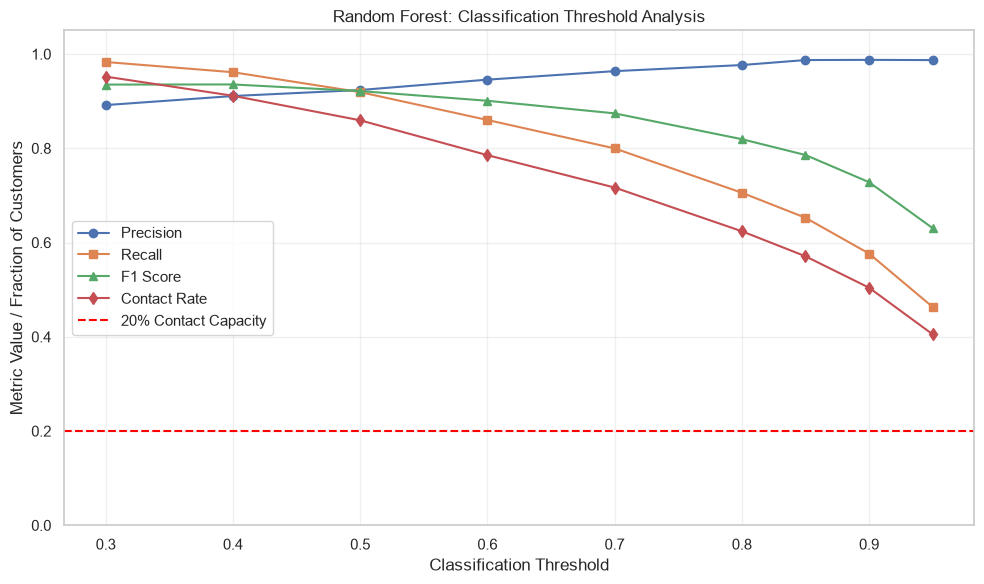

In [68]:
# ==========================================
# 8.3 Precision-Recall Threshold Visualization
# ==========================================

fig, ax = plt.subplots(figsize=(10, 6))

ax.plot(
    threshold_df["Threshold"],
    threshold_df["Precision"],
    marker="o",
    label="Precision"
)

ax.plot(
    threshold_df["Threshold"],
    threshold_df["Recall"],
    marker="s",
    label="Recall"
)

ax.plot(
    threshold_df["Threshold"],
    threshold_df["F1"],
    marker="^",
    label="F1 Score"
)

ax.plot(
    threshold_df["Threshold"],
    threshold_df["Contact Rate"],
    marker="d",
    label="Contact Rate"
)

ax.axhline(
    y=0.20,
    color="red",
    linestyle="--",
    label="20% Contact Capacity"
)

ax.set_title(
    "Random Forest: Classification Threshold Analysis"
)

ax.set_xlabel("Classification Threshold")
ax.set_ylabel("Metric Value / Fraction of Customers")
ax.set_ylim(0, 1.05)

ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "17_rf_threshold_analysis.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [69]:
# ==========================================
# 8.4 Top 20% Customer Risk Selection
# ==========================================

CONTACT_FRACTION = 0.20

n_customers = len(X_train)

contact_budget = int(
    np.ceil(n_customers * CONTACT_FRACTION)
)

# Rank by decreasing predicted churn probability
ranked_indices = np.argsort(
    -rf_tuned_oof_probabilities,
    kind="stable"
)

# Select highest-risk customers
top20_indices = ranked_indices[:contact_budget]

# Actual labels
actual_churn = y_train.to_numpy()

# Actual churners captured
captured_churners = int(
    actual_churn[top20_indices].sum()
)

total_churners = int(actual_churn.sum())

# Calculate business metrics
precision_at_20 = (
    captured_churners / contact_budget
)

recall_at_20 = (
    captured_churners / total_churners
)

# Expected performance of random customer selection
random_expected_churners = (
    contact_budget * actual_churn.mean()
)

lift_at_20 = (
    captured_churners / random_expected_churners
)

# Empirical probability cutoff
top20_cutoff = float(
    rf_tuned_oof_probabilities[top20_indices[-1]]
)

print("=" * 50)
print("TOP 20% RETENTION ANALYSIS")
print("=" * 50)

print("Total customers:", n_customers)
print("Contact budget:", contact_budget)
print("Total actual churners:", total_churners)

print("\nModel results:")
print("Actual churners captured:", captured_churners)
print("Precision@20%:", round(precision_at_20, 4))
print("Recall@20%:", round(recall_at_20, 4))

print("\nRandom selection comparison:")
print("Expected random captures:",
      round(random_expected_churners, 2))

print("Lift over random:",
      round(lift_at_20, 4))

print("\nTop-20% probability cutoff:",
      round(top20_cutoff, 4))

TOP 20% RETENTION ANALYSIS
Total customers: 960
Contact budget: 192
Total actual churners: 829

Model results:
Actual churners captured: 191
Precision@20%: 0.9948
Recall@20%: 0.2304

Random selection comparison:
Expected random captures: 165.8
Lift over random: 1.152

Top-20% probability cutoff: 0.9925


In [70]:
# ==========================================
# 8.5 Save Threshold and Top-20% Results
# ==========================================

threshold_df.to_csv(
    REPORTS_DIR / "threshold_analysis.csv",
    index=False
)

top20_summary = pd.DataFrame([{
    "Total Customers": n_customers,
    "Contact Budget": contact_budget,
    "Actual Churners": total_churners,
    "Captured Churners": captured_churners,
    "Precision at 20%": precision_at_20,
    "Recall at 20%": recall_at_20,
    "Random Expected Captures": random_expected_churners,
    "Lift Over Random": lift_at_20,
    "Development Probability Cutoff": top20_cutoff
}])

top20_summary.to_csv(
    REPORTS_DIR / "top20_development_results.csv",
    index=False
)

print("Threshold and top-20% results saved!")

Threshold and top-20% results saved!


### 8.6 Threshold Analysis and Business Interpretation

The tuned Random Forest model was evaluated across nine classification thresholds ranging from 0.30 to 0.95.

Precision, recall, F1 score, balanced accuracy, and the proportion of customers predicted to churn were calculated at each threshold.

Increasing the classification threshold generally reduces the number of customers classified as high risk, creating a trade-off between contact volume, precision, and recall.

### Business Contact Constraint

The company is assumed to have sufficient resources to contact only 20% of customers during a retention cycle.

To satisfy this requirement, customers were ranked by their predicted churn probabilities, and the highest-risk 20% were selected.

This approach is preferable to assuming that a universal probability threshold of 0.50 satisfies the contact-capacity constraint.

### Random Selection Benchmark

The model-selected group is compared with the expected number of churners identified through randomly contacting the same number of customers.

Precision@20%, Recall@20%, and Lift@20% are used to quantify the effectiveness of the risk-based selection strategy.

### Methodological Limitation

The analysis uses out-of-fold predictions from the training dataset. Hyperparameters were previously selected using this dataset, so the development estimates may contain selection optimism.

The final contact-ranking performance will be assessed later using the held-out test dataset.

No final model-selection or threshold decisions are based on test-set outcomes.

## 9. Probability Calibration

### Objective

This section evaluates the reliability of predicted customer churn probabilities.

Although ROC-AUC and PR-AUC measure ranking performance, they do not establish whether predicted probabilities accurately represent observed churn frequencies.

The tuned Random Forest model produces very high probabilities for some customers. Therefore, probability calibration is investigated.

The following approaches are compared:

1. Uncalibrated Random Forest
2. Sigmoid-calibrated Random Forest

Evaluation metrics include:

- Brier Score
- Log Loss
- ROC-AUC
- Average Precision

Calibration curves are also used to compare predicted probabilities against observed churn frequencies.

Cross-validation is used to avoid fitting and evaluating probability calibration on the same observations.

The final held-out test dataset remains untouched.

In [71]:
# ==========================================
# 9.1 Create Calibrated Random Forest
# ==========================================

from sklearn.calibration import (
    CalibratedClassifierCV,
    calibration_curve
)

from sklearn.metrics import (
    brier_score_loss,
    log_loss
)

from sklearn.base import clone

# Use the previously tuned Random Forest
calibrated_rf_pipeline = CalibratedClassifierCV(
    estimator=clone(rf_random_search.best_estimator_),
    method="sigmoid",
    cv=3,
    ensemble=True,
    n_jobs=1
)

print("Calibrated Random Forest configured successfully!")

Calibrated Random Forest configured successfully!


In [72]:
# ==========================================
# 9.2 Generate Calibrated OOF Probabilities
# ==========================================

calibrated_oof_probabilities = cross_val_predict(
    calibrated_rf_pipeline,
    X_train,
    y_train,
    cv=cv,
    method="predict_proba",
    n_jobs=1
)[:, 1]

print("Calibration cross-validation completed!")

print(
    "Number of probabilities:",
    len(calibrated_oof_probabilities)
)

print(
    "Minimum probability:",
    round(calibrated_oof_probabilities.min(), 4)
)

print(
    "Maximum probability:",
    round(calibrated_oof_probabilities.max(), 4)
)

Calibration cross-validation completed!
Number of probabilities: 960
Minimum probability: 0.1872
Maximum probability: 0.9748


In [73]:
# ==========================================
# 9.3 Compare Calibration Metrics
# ==========================================

calibration_results = pd.DataFrame({
    "Model": [
        "Uncalibrated Random Forest",
        "Calibrated Random Forest"
    ],

    "Brier Score": [
        brier_score_loss(
            y_train,
            rf_tuned_oof_probabilities
        ),
        brier_score_loss(
            y_train,
            calibrated_oof_probabilities
        )
    ],

    "Log Loss": [
        log_loss(
            y_train,
            rf_tuned_oof_probabilities
        ),
        log_loss(
            y_train,
            calibrated_oof_probabilities
        )
    ],

    "ROC-AUC": [
        roc_auc_score(
            y_train,
            rf_tuned_oof_probabilities
        ),
        roc_auc_score(
            y_train,
            calibrated_oof_probabilities
        )
    ],

    "PR-AUC": [
        average_precision_score(
            y_train,
            rf_tuned_oof_probabilities
        ),
        average_precision_score(
            y_train,
            calibrated_oof_probabilities
        )
    ]
})

display(calibration_results.round(4))

,Model,Brier Score,Log Loss,ROC-AUC,PR-AUC
0,Uncalibrated Random Forest,0.0917,0.3249,0.8778,0.9754
1,Calibrated Random Forest,0.0842,0.2783,0.8737,0.9710


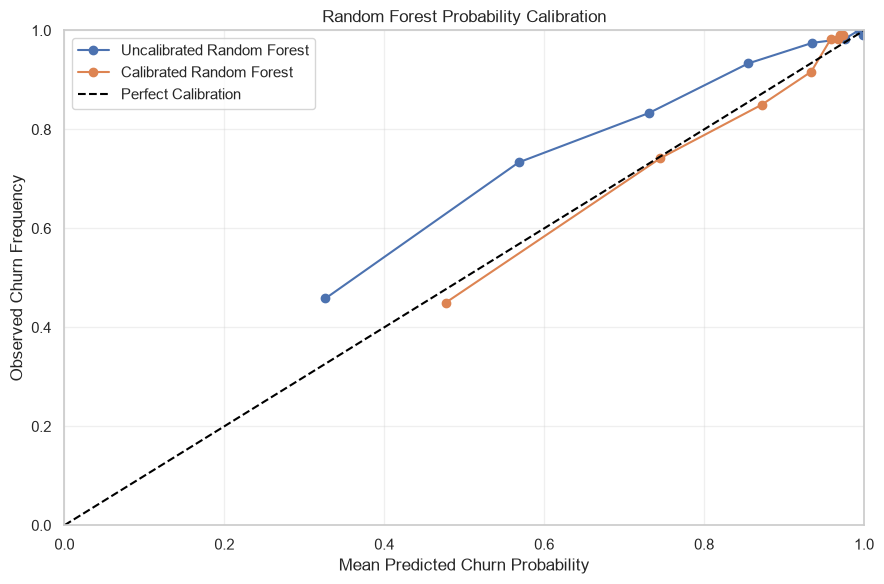

In [74]:
# ==========================================
# 9.4 Calibration Curve
# ==========================================

fig, ax = plt.subplots(figsize=(9, 6))

models_for_calibration = {
    "Uncalibrated Random Forest":
        rf_tuned_oof_probabilities,

    "Calibrated Random Forest":
        calibrated_oof_probabilities
}

for model_name, probabilities in models_for_calibration.items():

    observed_rate, mean_probability = calibration_curve(
        y_train,
        probabilities,
        n_bins=8,
        strategy="quantile"
    )

    ax.plot(
        mean_probability,
        observed_rate,
        marker="o",
        label=model_name
    )

# Perfect calibration reference
ax.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="black",
    label="Perfect Calibration"
)

ax.set_title("Random Forest Probability Calibration")

ax.set_xlabel("Mean Predicted Churn Probability")
ax.set_ylabel("Observed Churn Frequency")

ax.set_xlim(0, 1)
ax.set_ylim(0, 1)

ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "18_probability_calibration.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [75]:
# ==========================================
# 9.5 Compare Top-20% Targeting
# ==========================================

def evaluate_top20(probabilities, model_name):

    labels = y_train.to_numpy()

    budget = int(np.ceil(len(labels) * 0.20))

    ranked_indices = np.argsort(
        -probabilities,
        kind="stable"
    )

    selected = ranked_indices[:budget]

    captured = int(labels[selected].sum())

    expected_random = budget * labels.mean()

    return {
        "Model": model_name,
        "Contact Budget": budget,
        "Captured Churners": captured,
        "Precision@20%": captured / budget,
        "Recall@20%": captured / labels.sum(),
        "Lift@20%": captured / expected_random
    }


calibration_top20 = pd.DataFrame([
    evaluate_top20(
        rf_tuned_oof_probabilities,
        "Uncalibrated Random Forest"
    ),

    evaluate_top20(
        calibrated_oof_probabilities,
        "Calibrated Random Forest"
    )
])

display(calibration_top20.round(4))

,Model,Contact Budget,Captured Churners,Precision@20%,Recall@20%,Lift@20%
0,Uncalibrated Random Forest,192,191,0.9948,0.2304,1.152
1,Calibrated Random Forest,192,190,0.9896,0.2292,1.146


In [76]:
# ==========================================
# 9.6 Save Calibration Results
# ==========================================

calibration_results.to_csv(
    REPORTS_DIR / "calibration_metrics.csv",
    index=False
)

calibration_top20.to_csv(
    REPORTS_DIR / "calibration_top20_comparison.csv",
    index=False
)

print("Calibration results saved successfully!")

Calibration results saved successfully!


### 9.7 Probability Calibration Methodology

Probability calibration was investigated to assess whether the tuned Random Forest model produces reliable estimates of customer churn risk.

The original tuned Random Forest was compared against a sigmoid-calibrated version.

Five-fold out-of-fold predictions were generated, with three-fold internal cross-validation used for probability calibration.

The evaluation considered:

- Brier Score
- Log Loss
- ROC-AUC
- Average Precision
- Calibration Curves
- Top-20% Retention Targeting Performance

Brier Score and Log Loss measure probability prediction quality, while ROC-AUC and average precision assess ranking performance.

A calibration curve compares average predicted churn probabilities with observed churn frequencies.

The evaluation also compares how many actual churners are captured when selecting the highest-risk 20% of customers.

Calibration is not assumed to improve performance automatically. Its value must be established using the resulting evaluation metrics.

Model hyperparameters were selected previously using the overall training dataset, so the cross-validated calibration results remain development estimates with potential selection optimism.

The final held-out test dataset remains untouched.

The choice between calibrated and uncalibrated predictions will consider both probability reliability and business targeting performance.

### 9.8 Probability Calibration Results

The tuned Random Forest model was compared against a sigmoid-calibrated version using cross-validated training predictions.

| Metric | Uncalibrated | Calibrated |
|---|---:|---:|
| Brier Score | 0.0917 | 0.0842 |
| Log Loss | 0.3249 | 0.2783 |
| ROC-AUC | 0.8778 | 0.8737 |
| Average Precision | 0.9754 | 0.9710 |
| Top-20% Churners Captured | 191 | 190 |
| Precision@20% | 0.9948 | 0.9896 |
| Recall@20% | 0.2304 | 0.2292 |

**Interpretation**

Probability calibration reduced Brier Score by approximately 8.2% and Log Loss by approximately 14.3%, indicating improved probability estimation.

The calibrated model experienced small reductions in ROC-AUC and average precision. However, the number of actual churners captured in the highest-risk 20% decreased by only one customer.

**Development Decision**

The calibrated Random Forest is selected as the leading candidate because it offers improved probability reliability while maintaining strong customer risk-ranking performance.

The uncalibrated Random Forest will be retained as a comparison model.

The selection remains provisional until final evaluation using the untouched test dataset.

The analysis demonstrates that discrimination, calibration, and business targeting performance should be assessed separately.

## 10. Model Explainability

### Objective

This section investigates how customer attributes influence predictions produced by the calibrated Random Forest model.

Two complementary explainability techniques are used:

1. Global permutation feature importance.
2. Individual customer-level feature sensitivity analysis.

Permutation importance measures how much model performance changes when individual features are shuffled.

Customer-level sensitivity analysis investigates how individual predictions change when customer attributes are replaced with representative reference values.

The analysis uses a separate development validation subset drawn from the training dataset.

The final held-out test dataset remains untouched.

Explanations describe predictive associations and model behavior, not causal relationships.

In [77]:
# ==========================================
# 10.1 Prepare Explainability Dataset
# ==========================================

from sklearn.base import clone
from sklearn.inspection import permutation_importance
from sklearn.model_selection import train_test_split

# Create internal development split
X_explain_fit, X_explain_val, y_explain_fit, y_explain_val = (
    train_test_split(
        X_train,
        y_train,
        test_size=0.25,
        stratify=y_train,
        random_state=RANDOM_STATE
    )
)

# Clone calibrated Random Forest
explain_model = clone(calibrated_rf_pipeline)

# Fit using only the explanation training subset
explain_model.fit(
    X_explain_fit,
    y_explain_fit
)

print("Explainability model trained successfully!")

print("Explanation training records:", len(X_explain_fit))
print("Explanation validation records:", len(X_explain_val))

Explainability model trained successfully!
Explanation training records: 720
Explanation validation records: 240


In [78]:
# ==========================================
# 10.2 Global Permutation Importance
# ==========================================

importance_results = permutation_importance(
    estimator=explain_model,
    X=X_explain_val,
    y=y_explain_val,
    scoring="roc_auc",
    n_repeats=3,
    random_state=RANDOM_STATE,
    n_jobs=1
)

importance_df = pd.DataFrame({
    "Feature": X_explain_val.columns,
    "Importance Mean": importance_results.importances_mean,
    "Importance Std": importance_results.importances_std
})

importance_df = importance_df.sort_values(
    "Importance Mean",
    ascending=False
)

print("GLOBAL FEATURE IMPORTANCE")
print("=" * 50)

display(importance_df.round(4))

GLOBAL FEATURE IMPORTANCE


,Feature,Importance Mean,Importance Std
14,monthly_usage_gb,0.3454,0.0526
2,contract_type,0.0382,0.0059
5,monthly_charges,0.0170,0.0061
13,satisfaction_score,0.0059,0.0022
1,tenure_months,0.0058,0.0011
0,age,0.0054,0.0074
12,late_payments_last_12m,0.0016,0.0013
11,complaints_last_12m,0.0011,0.0021
8,dependents,0.0010,0.0005
3,internet_service,0.0000,0.0018


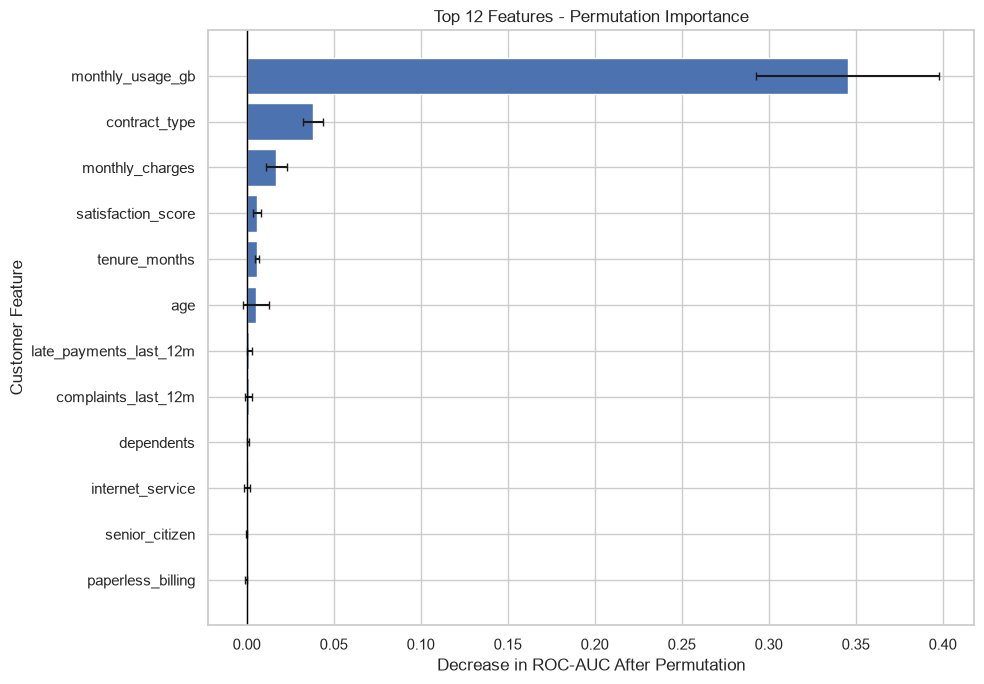

In [79]:
# ==========================================
# 10.3 Visualize Global Feature Importance
# ==========================================

top_features = (
    importance_df
    .head(12)
    .sort_values("Importance Mean")
)

fig, ax = plt.subplots(figsize=(10, 7))

ax.barh(
    top_features["Feature"],
    top_features["Importance Mean"],
    xerr=top_features["Importance Std"],
    capsize=3
)

ax.axvline(
    x=0,
    color="black",
    linewidth=1
)

ax.set_title(
    "Top 12 Features - Permutation Importance"
)

ax.set_xlabel("Decrease in ROC-AUC After Permutation")
ax.set_ylabel("Customer Feature")

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "19_global_feature_importance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [80]:
# ==========================================
# 10.4 Select Three Customers
# ==========================================

explain_probabilities = explain_model.predict_proba(
    X_explain_val
)[:, 1]

sorted_positions = np.argsort(explain_probabilities)

selected_customers = {
    "Highest Predicted Risk": int(sorted_positions[-1]),
    "Median Predicted Risk": int(
        sorted_positions[len(sorted_positions) // 2]
    ),
    "Lowest Predicted Risk": int(sorted_positions[0])
}

customer_summaries = []

for label, position in selected_customers.items():

    customer_index = X_explain_val.index[position]

    customer_summaries.append({
        "Risk Group": label,
        "Customer ID": df_train.loc[
            customer_index, "customer_id"
        ],
        "Predicted Churn Probability":
            explain_probabilities[position],
        "Actual Churn":
            int(y_explain_val.iloc[position])
    })

customer_summary_df = pd.DataFrame(customer_summaries)

display(customer_summary_df.round(4))

,Risk Group,Customer ID,Predicted Churn Probability,Actual Churn
0,Highest Predicted Risk,CUST100923,0.9659,1
1,Median Predicted Risk,CUST100371,0.9391,1
2,Lowest Predicted Risk,CUST100267,0.2715,0


In [81]:
# ==========================================
# 10.5 Individual Customer Explanations
# ==========================================

# Calculate reference values using explanation training data
reference_values = {}

for column in X_explain_fit.columns:

    series = X_explain_fit[column]

    if pd.api.types.is_numeric_dtype(series):

        reference = series.median()

        if pd.api.types.is_integer_dtype(series):
            reference = int(round(reference))

    else:
        reference = series.mode(dropna=True).iloc[0]

    reference_values[column] = reference


local_explanations = []

for label, position in selected_customers.items():

    customer_index = X_explain_val.index[position]

    customer = X_explain_val.loc[
        [customer_index]
    ].copy()

    original_probability = float(
        explain_model.predict_proba(customer)[0, 1]
    )

    for feature in X_explain_fit.columns:

        original_value = customer.iloc[0][feature]
        reference_value = reference_values[feature]

        # Skip features already at reference value
        if (
            pd.notna(original_value)
            and original_value == reference_value
        ):
            continue

        modified_customer = customer.copy()

        modified_customer[feature] = reference_value

        modified_probability = float(
            explain_model.predict_proba(
                modified_customer
            )[0, 1]
        )

        local_explanations.append({
            "Risk Group": label,
            "Customer ID": df_train.loc[
                customer_index, "customer_id"
            ],
            "Feature": feature,
            "Original Value": original_value,
            "Reference Value": reference_value,
            "Original Probability": original_probability,
            "Modified Probability": modified_probability,
            "Probability Change": (
                original_probability - modified_probability
            )
        })


local_explanations_df = pd.DataFrame(
    local_explanations
)

for label in selected_customers:

    print("\n" + "=" * 60)
    print(label)
    print("=" * 60)

    customer_results = local_explanations_df[
        local_explanations_df["Risk Group"] == label
    ].copy()

    customer_results["Absolute Change"] = (
        customer_results["Probability Change"].abs()
    )

    customer_results = customer_results.sort_values(
        "Absolute Change",
        ascending=False
    )

    display(
        customer_results[
            [
                "Feature",
                "Original Value",
                "Reference Value",
                "Original Probability",
                "Modified Probability",
                "Probability Change"
            ]
        ].head(5).round(4)
    )


Highest Predicted Risk


,Feature,Original Value,Reference Value,Original Probability,Modified Probability,Probability Change
10,monthly_usage_gb,113.6,65.6,0.9659,0.8458,0.1201
1,tenure_months,42,35,0.9659,0.9658,0.0002
11,discount_pct,4.59,8.59,0.9659,0.9658,0.0002
8,complaints_last_12m,0,1,0.9659,0.9660,-0.0001
4,payment_method,Bank transfer,Electronic check,0.9659,0.9658,0.0001



Median Predicted Risk


,Feature,Original Value,Reference Value,Original Probability,Modified Probability,Probability Change
15,region,Sabaragamuwa,Western,0.9391,0.9513,-0.0122
18,late_payments_last_12m,2,1,0.9391,0.9344,0.0047
20,monthly_usage_gb,57.9,65.6,0.9391,0.9347,0.0044
21,discount_pct,0.0,8.59,0.9391,0.9433,-0.0042
16,monthly_charges,120.21,71.68,0.9391,0.9428,-0.0037



Lowest Predicted Risk


,Feature,Original Value,Reference Value,Original Probability,Modified Probability,Probability Change
33,monthly_usage_gb,11.3,65.6,0.2715,0.7874,-0.5159
24,contract_type,One year,Month-to-month,0.2715,0.3767,-0.1052
32,satisfaction_score,9.7,6.8,0.2715,0.3131,-0.0416
31,late_payments_last_12m,2,1,0.2715,0.2320,0.0395
30,complaints_last_12m,0,1,0.2715,0.3102,-0.0388


In [82]:
# ==========================================
# 10.6 Save Explainability Results
# ==========================================

importance_df.to_csv(
    REPORTS_DIR / "global_feature_importance.csv",
    index=False
)

customer_summary_df.to_csv(
    REPORTS_DIR / "customer_explanation_summary.csv",
    index=False
)

local_explanations_df.to_csv(
    REPORTS_DIR / "individual_customer_explanations.csv",
    index=False
)

print("Explainability results saved successfully!")

Explainability results saved successfully!


### 10.7 Explainability Methodology

The calibrated Random Forest model was analyzed using global permutation importance and individual customer-level feature sensitivity analysis.

**Global Explainability**

Permutation importance was calculated using an internal validation subset of the training data.

Each input feature was randomly shuffled three times, and the corresponding change in ROC-AUC was measured.

Features producing larger decreases in ROC-AUC were considered more important for model discrimination in this experiment.

**Individual Explainability**

Three customers were selected to represent the highest, median, and lowest predicted churn risks within the explanation validation subset.

For each customer, individual input attributes were replaced with reference values calculated from the explanation training subset.

Changes in predicted churn probability were measured to identify attributes to which each prediction was most sensitive.

**Limitations**

Permutation importance may underestimate the importance of correlated features.

Individual sensitivity measurements are reference-dependent and do not provide additive feature attributions.

The explanations describe the behavior of the fitted machine learning model and should not be interpreted as evidence of causal relationships.

All explainability experiments used training-derived data. The final test dataset remained untouched.

### 10.8 Explainability Results and Interpretation

#### Global Feature Importance

Permutation importance identified monthly_usage_gb as the most influential predictor, with a mean importance of 0.3454.

The next most important features were:

- contract_type: 0.0382
- monthly_charges: 0.0170
- satisfaction_score: 0.0059
- tenure_months: 0.0058
- age: 0.0054

Monthly usage had substantially greater importance than the other features.

This finding suggests that the model relies heavily on customer usage patterns when ranking churn risk.

However, earlier data-quality checks identified inconsistencies between internet-service categories and recorded usage. Consequently, the importance of monthly usage requires further robustness analysis.

#### Individual Customer Explanations

**Customer 1: Highest Predicted Risk**

The predicted churn probability was 0.9659.

Replacing monthly usage of 113.6 GB with the reference value of 65.6 GB reduced the predicted probability to 0.8458.

This indicates that the prediction is particularly sensitive to this customer's monthly usage.

**Customer 2: Median Predicted Risk**

The predicted churn probability was 0.9391.

Region, late-payment history, usage, discounts, and monthly charges produced relatively small changes in the predicted probability when replaced with reference values.

Although this customer represents the median predicted risk within the selected sample, the absolute predicted probability remains high.

**Customer 3: Lowest Predicted Risk**

The predicted churn probability was 0.2715.

Replacing monthly usage of 11.3 GB with the reference value of 65.6 GB increased the predicted probability to 0.7874.

Changing the contract from one year to month-to-month also increased the predicted probability, from 0.2715 to 0.3767.

Reducing satisfaction from 9.7 to 6.8 increased the predicted probability to 0.3131.

#### Business Interpretation

Monthly usage, contract type, monthly charges, and customer satisfaction are useful indicators for investigating churn risk.

However, predictive feature importance does not establish causation.

The company should not assume that reducing usage or changing contract terms would automatically reduce customer churn.

The results should instead guide further customer research and the design of retention interventions.

#### Limitations

Individual sensitivity analysis depends on the selected reference values and may produce unrealistic combinations of customer attributes.

Correlations between features can influence permutation importance.

The strong dependence on monthly usage should be evaluated through an additional robustness experiment before final model selection.

## 11. Customer Retention Cost-Benefit Simulation

### Objective

This section evaluates the potential financial value of targeting customers using predicted churn probabilities.

The company's retention team is assumed to have capacity to contact only 20% of customers during each retention cycle.

Two strategies are compared:

1. Model-based selection of the highest-risk 20%.
2. Random selection of 20% of customers.

The simulation uses hypothetical assumptions about customer contact costs, retention effectiveness, and the financial contribution of retained customers.

The analysis distinguishes between customers identified as likely churners and customers whose churn would actually be prevented by an intervention.

The results are illustrative development estimates rather than experimentally verified business outcomes.

In [83]:
# ==========================================
# 11.1 Retention Cost-Benefit Simulation
# ==========================================

# Hypothetical business assumptions
CONTACT_RATE = 0.20
CONTACT_COST = 5
RETAINED_CUSTOMER_VALUE = 120
RETENTION_SUCCESS_RATE = 0.25

# Use development training labels
actual_labels = y_train.to_numpy()

# Use calibrated Random Forest OOF probabilities
risk_probabilities = calibrated_oof_probabilities

# Calculate contact capacity
total_customers = len(actual_labels)

contact_budget = int(
    np.ceil(total_customers * CONTACT_RATE)
)

# Rank customers by churn risk
risk_ranking = np.argsort(
    -risk_probabilities,
    kind="stable"
)

selected_customers = risk_ranking[:contact_budget]

# Model-based results
model_captured = int(
    actual_labels[selected_customers].sum()
)

# Expected random selection results
random_captured = (
    contact_budget * actual_labels.mean()
)

# Expected successfully retained customers
model_retained = (
    model_captured * RETENTION_SUCCESS_RATE
)

random_retained = (
    random_captured * RETENTION_SUCCESS_RATE
)

# Gross financial benefit
model_gross_benefit = (
    model_retained * RETAINED_CUSTOMER_VALUE
)

random_gross_benefit = (
    random_retained * RETAINED_CUSTOMER_VALUE
)

# Same contact cost for both strategies
total_contact_cost = (
    contact_budget * CONTACT_COST
)

# Net financial benefit
model_net_benefit = (
    model_gross_benefit - total_contact_cost
)

random_net_benefit = (
    random_gross_benefit - total_contact_cost
)

# Incremental benefit from model-based targeting
incremental_benefit = (
    model_net_benefit - random_net_benefit
)

# Build comparison table
business_results = pd.DataFrame({
    "Metric": [
        "Customers Contacted",
        "Churners Identified",
        "Expected Customers Retained",
        "Gross Benefit (CU)",
        "Contact Cost (CU)",
        "Net Benefit (CU)"
    ],

    "Random Selection": [
        contact_budget,
        random_captured,
        random_retained,
        random_gross_benefit,
        total_contact_cost,
        random_net_benefit
    ],

    "Calibrated Random Forest": [
        contact_budget,
        model_captured,
        model_retained,
        model_gross_benefit,
        total_contact_cost,
        model_net_benefit
    ]
})

print("CUSTOMER RETENTION COST-BENEFIT ANALYSIS")
print("=" * 55)

display(business_results.round(2))

print(
    "\nIncremental Net Benefit:",
    round(incremental_benefit, 2),
    "CU"
)

CUSTOMER RETENTION COST-BENEFIT ANALYSIS


,Metric,Random Selection,Calibrated Random Forest
0,Customers Contacted,192.00,192.0
1,Churners Identified,165.80,190.0
2,Expected Customers Retained,41.45,47.5
3,Gross Benefit (CU),4974.00,5700.0
4,Contact Cost (CU),960.00,960.0
5,Net Benefit (CU),4014.00,4740.0



Incremental Net Benefit: 726.0 CU


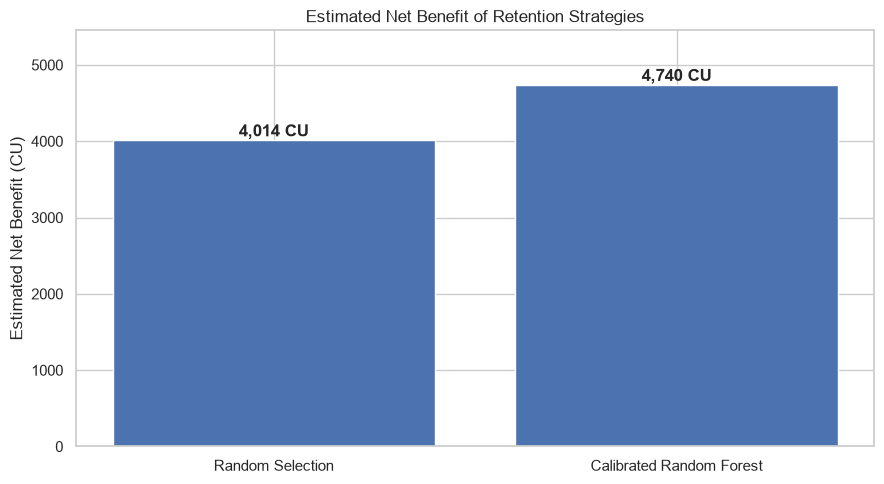

In [84]:
# ==========================================
# 11.2 Visualize Business Impact
# ==========================================

strategies = [
    "Random Selection",
    "Calibrated Random Forest"
]

net_benefits = [
    random_net_benefit,
    model_net_benefit
]

fig, ax = plt.subplots(figsize=(9, 5))

bars = ax.bar(
    strategies,
    net_benefits
)

for bar, value in zip(bars, net_benefits):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 50,
        f"{value:,.0f} CU",
        ha="center",
        fontweight="bold"
    )

ax.set_title(
    "Estimated Net Benefit of Retention Strategies"
)

ax.set_ylabel("Estimated Net Benefit (CU)")

ax.set_ylim(
    0,
    max(net_benefits) * 1.15
)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "20_retention_business_impact.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [85]:
# ==========================================
# 11.3 Business Assumption Sensitivity
# ==========================================

success_rates = [0.10, 0.20, 0.25, 0.35, 0.50]

customer_values = [80, 120, 160]

sensitivity_results = []

for success_rate in success_rates:

    for customer_value in customer_values:

        model_benefit = (
            model_captured
            * success_rate
            * customer_value
            - total_contact_cost
        )

        random_benefit = (
            random_captured
            * success_rate
            * customer_value
            - total_contact_cost
        )

        sensitivity_results.append({
            "Retention Success Rate": success_rate,
            "Retained Customer Value": customer_value,
            "Model Net Benefit": model_benefit,
            "Random Net Benefit": random_benefit,
            "Incremental Benefit": (
                model_benefit - random_benefit
            )
        })

sensitivity_df = pd.DataFrame(sensitivity_results)

display(sensitivity_df.round(2))

,Retention Success Rate,Retained Customer Value,Model Net Benefit,Random Net Benefit,Incremental Benefit
0,0.10,80,560.0,366.4,193.6
1,0.10,120,1320.0,1029.6,290.4
2,0.10,160,2080.0,1692.8,387.2
3,0.20,80,2080.0,1692.8,387.2
4,0.20,120,3600.0,3019.2,580.8
5,0.20,160,5120.0,4345.6,774.4
6,0.25,80,2840.0,2356.0,484.0
7,0.25,120,4740.0,4014.0,726.0
8,0.25,160,6640.0,5672.0,968.0
9,0.35,80,4360.0,3682.4,677.6


In [86]:
# ==========================================
# 11.4 Save Business Simulation Results
# ==========================================

business_results.to_csv(
    REPORTS_DIR / "retention_business_simulation.csv",
    index=False
)

sensitivity_df.to_csv(
    REPORTS_DIR / "retention_sensitivity_analysis.csv",
    index=False
)

print("Business simulation results saved successfully!")

Business simulation results saved successfully!


### 11.5 Retention Simulation Results

A hypothetical cost-benefit simulation was conducted to evaluate the business value of model-based retention targeting.

#### Assumptions

- Customer contact capacity: 20%
- Cost per customer contact: 5 currency units
- Value per successfully retained customer: 120 currency units
- Retention intervention success rate: 25%

These assumptions are hypothetical and do not represent verified company financial data.

#### Model-Based Targeting

The calibrated Random Forest identified 190 actual churners among the 192 highest-risk customers selected from the development dataset.

Under the assumed intervention effectiveness, the expected number of successfully retained customers is 47.5.

The estimated gross benefit is 5,700 currency units.

After deducting 960 currency units in customer contact costs, the expected net benefit is 4,740 currency units.

#### Random Selection

Randomly contacting 192 customers would identify approximately 165.8 actual churners on average.

Under the same retention assumptions, approximately 41.45 customers would be retained in expectation.

The estimated net benefit is 4,014 currency units.

#### Incremental Business Value

Model-based targeting produces an estimated incremental net benefit of 726 currency units compared with random selection.

This improvement is attributable to identifying more customers who would otherwise churn under the hypothetical intervention assumptions.

#### Sensitivity Analysis

Additional scenarios were evaluated using different retention success rates and retained-customer values.

These scenarios demonstrate that expected financial outcomes depend on intervention effectiveness and customer contribution.

#### Limitations

The simulation uses cross-validated development predictions rather than independent final test results.

Historical churn outcomes do not establish which customers can actually be persuaded to remain.

The retention success rate and customer value are hypothetical.

Therefore, the estimated financial benefits should be interpreted as scenario-based projections rather than verified financial returns.

A controlled retention campaign or randomized experiment would be required to estimate actual incremental intervention effectiveness.

### 11.6 Business Simulation Findings

The calibrated Random Forest was evaluated using a hypothetical customer retention simulation with a contact capacity of 20%.

Under the baseline assumptions, the model-based strategy produced an estimated net benefit of 4,740 currency units, compared with 4,014 currency units from random selection.

The estimated incremental net benefit was 726 currency units, representing an approximately 18.1% improvement over random selection.

The model-based strategy identified 190 actual churners among 192 selected customers, compared with an expected 165.8 churners from random selection.

Sensitivity analysis varied the intervention success rate from 10% to 50% and retained-customer value from 80 to 160 currency units.

The resulting incremental benefits ranged from 193.60 to 1,936 currency units.

These results suggest that risk-based customer targeting has potential business value.

However, the results are based on development data and hypothetical financial assumptions.

Predicting churn does not establish which customers can be successfully retained through an intervention.

Therefore, the financial estimates should be interpreted as illustrative scenarios rather than verified business returns.

## 12. Model Robustness Testing

### Objective

This section evaluates the sensitivity of Random Forest performance to the availability of monthly usage information.

Previous explainability analysis showed that monthly_usage_gb was the most important predictor.

However, the data audit also identified inconsistencies between internet_service and monthly_usage_gb.

To investigate this issue, two configurations are compared:

1. Tuned Random Forest with the complete feature set.
2. Tuned Random Forest excluding monthly_usage_gb and the derived monthly_charge_per_gb feature.

Both models use identical hyperparameters and stratified 5-fold cross-validation.

The experiment evaluates ROC-AUC, average precision, balanced accuracy, and fold-to-fold variation.

The final test dataset remains untouched.

In [92]:
# ==========================================
# 12.1 Build Robustness Experiment Pipelines
# ==========================================

from sklearn.base import clone
from src.robustness import DropColumnsTransformer

# Original tuned Random Forest
full_feature_model = clone(
    rf_random_search.best_estimator_
)

# Create independent model copy
reduced_feature_model = clone(
    rf_random_search.best_estimator_
)

# Remove usage after feature engineering,
# but before numerical/categorical preprocessing

reduced_feature_model.steps.insert(
    1,
    (
        "drop_usage_features",
        DropColumnsTransformer(
            columns=[
                "monthly_usage_gb",
                "monthly_charge_per_gb"
            ]
        )
    )
)

print("Full-feature model created!")
print("Reduced-feature model created!")

print("\nReduced-feature pipeline:")
print(reduced_feature_model)

Full-feature model created!
Reduced-feature model created!

Reduced-feature pipeline:
Pipeline(steps=[('feature_engineering', ChurnFeatureEngineer()),
                ('drop_usage_features',
                 DropColumnsTransformer(columns=['monthly_usage_gb',
                                                 'monthly_charge_per_gb'])),
                ('preprocessor',
                 ColumnTransformer(sparse_threshold=0,
                                   transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(add_indicator=True,
                                                                                 strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  <s...
                

In [93]:
# ==========================================
# 12.2 Evaluate Robustness
# ==========================================

robustness_scoring = {
    "roc_auc": "roc_auc",
    "pr_auc": "average_precision",
    "balanced_accuracy": "balanced_accuracy"
}

# Original model
full_results = cross_validate(
    full_feature_model,
    X_train,
    y_train,
    cv=cv,
    scoring=robustness_scoring,
    return_train_score=True,
    n_jobs=1,
    error_score="raise"
)

# Model without monthly usage information
reduced_results = cross_validate(
    reduced_feature_model,
    X_train,
    y_train,
    cv=cv,
    scoring=robustness_scoring,
    return_train_score=True,
    n_jobs=1,
    error_score="raise"
)

print("Robustness testing completed successfully!")

Robustness testing completed successfully!


In [94]:
# ==========================================
# 12.3 Robustness Comparison Table
# ==========================================

robustness_rows = []

experiments = {
    "Full Feature Model": full_results,
    "Without Monthly Usage": reduced_results
}

for model_name, results in experiments.items():

    train_roc_auc = results[
        "train_roc_auc"
    ].mean()

    validation_roc_auc = results[
        "test_roc_auc"
    ].mean()

    robustness_rows.append({
        "Model": model_name,

        "Train ROC-AUC": train_roc_auc,

        "Validation ROC-AUC": validation_roc_auc,

        "ROC-AUC Fold Std":
            results["test_roc_auc"].std(),

        "PR-AUC":
            results["test_pr_auc"].mean(),

        "Balanced Accuracy":
            results["test_balanced_accuracy"].mean(),

        "Generalization Gap":
            train_roc_auc - validation_roc_auc
    })

robustness_comparison = pd.DataFrame(
    robustness_rows
)

display(robustness_comparison.round(4))

roc_auc_difference = (
    robustness_comparison.loc[
        0, "Validation ROC-AUC"
    ]
    -
    robustness_comparison.loc[
        1, "Validation ROC-AUC"
    ]
)

print(
    "\nROC-AUC decrease after removing usage:",
    round(roc_auc_difference, 4)
)

,Model,Train ROC-AUC,Validation ROC-AUC,ROC-AUC Fold Std,PR-AUC,Balanced Accuracy,Generalization Gap
0,Full Feature Model,0.9961,0.8811,0.0192,0.9770,0.7193,0.1151
1,Without Monthly Usage,0.9995,0.6192,0.0537,0.9071,0.5180,0.3803



ROC-AUC decrease after removing usage: 0.2619


In [95]:
# ==========================================
# 12.4 Save Robustness Results
# ==========================================

robustness_comparison.to_csv(
    REPORTS_DIR / "model_robustness_comparison.csv",
    index=False
)

print("Robustness results saved successfully!")

Robustness results saved successfully!


### 12.5 Robustness Testing Methodology

A feature-ablation experiment was performed to assess the model's reliance on monthly internet usage.

The original tuned Random Forest was compared against an otherwise identical configuration excluding monthly_usage_gb and monthly_charge_per_gb.

Removing both variables was necessary because monthly_charge_per_gb directly incorporates monthly usage information.

Both configurations used identical hyperparameters and stratified 5-fold cross-validation.

The experiment evaluated:

- Training ROC-AUC
- Validation ROC-AUC
- Validation ROC-AUC standard deviation
- Average precision
- Balanced accuracy
- Training-validation generalization gap

The purpose of the experiment was to determine whether predictive performance remained stable when potentially unreliable usage information was excluded.

The experiment used only development training data.

The final held-out test dataset remained untouched.

The experiment isolates sensitivity to feature removal under the existing tuned hyperparameters. It does not establish the optimal performance achievable after separately retuning the reduced-feature model.

Final conclusions will be recorded after reviewing the numerical results.

### 12.6 Robustness Testing Results and Interpretation

A feature-ablation experiment was performed to examine the Random Forest model's dependence on monthly_usage_gb and monthly_charge_per_gb.

**Full-Feature Model:**
- Training ROC-AUC: 0.9961
- Validation ROC-AUC: 0.8811
- PR-AUC: 0.9770
- Balanced Accuracy: 0.7193
- Generalization Gap: 0.1151

**Model Without Monthly Usage:**
- Training ROC-AUC: 0.9995
- Validation ROC-AUC: 0.6192
- PR-AUC: 0.9071
- Balanced Accuracy: 0.5180
- Generalization Gap: 0.3803

**Interpretation:**

Removing monthly usage and its derived charge-to-usage ratio reduced validation ROC-AUC by 0.2619.

This indicates that monthly usage information contributes substantially to the model's predictive performance.

The reduced-feature model exhibits substantial overfitting, with a training ROC-AUC of 0.9995 but a validation ROC-AUC of only 0.6192.

The full-feature model also demonstrates a training-validation performance gap, indicating some overfitting.

**Data Quality and Leakage Considerations:**

Previous analysis identified inconsistencies between internet_service and monthly_usage_gb.

Furthermore, the dataset does not establish whether monthly usage was recorded before the churn outcome.

Therefore, the strong reliance on monthly usage represents a potential data-quality and temporal-leakage risk requiring further investigation.

**Decision:**

The calibrated Random Forest using the full feature set is retained as the provisional research model.

Production deployment is not recommended until monthly usage has been verified as a reliable, pre-outcome predictor.

A separately optimized reduced-feature model should be considered if usage information cannot be validated.

The final held-out test dataset remains untouched.

## 13. Final Model Training and Independent Test Evaluation

### Objective

This section evaluates the selected calibrated Random Forest model using the previously untouched test dataset.

The model configuration was selected using training-data cross-validation, hyperparameter optimization, probability calibration, and robustness analysis.

The final model is fitted using all 960 training observations.

The remaining 240 test observations are used for independent evaluation.

### Evaluation Metrics

- Accuracy
- Balanced Accuracy
- Precision
- Recall
- F1 Score
- ROC-AUC
- Average Precision (PR-AUC)
- Brier Score
- Log Loss
- Confusion Matrix

A default threshold of 0.50 is reported for diagnostic classification metrics.

The operational retention strategy instead selects the highest-risk 20% of customers.

The final test results will not be used for additional model tuning.

The evaluation remains conditional on the assumption that all predictive features were available before the churn outcome.

In [96]:
# ==========================================
# 13.1 Prepare Final Test Dataset
# ==========================================

X_test = df_test.drop(
    columns=DROP_COLUMNS
).copy()

y_test = df_test["churn"].copy()

print("FINAL DATASET VERIFICATION")
print("=" * 50)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTest target distribution:")
print(y_test.value_counts())

# Verify identical input columns
assert X_train.columns.tolist() == X_test.columns.tolist()

# Verify no target or identifier leakage
assert "customer_id" not in X_test.columns
assert "churn" not in X_test.columns
assert "total_charges" not in X_test.columns

print("\nFinal test data verification passed!")

FINAL DATASET VERIFICATION
Training features: (960, 17)
Testing features: (240, 17)

Test target distribution:
churn
1    207
0     33
Name: count, dtype: int64

Final test data verification passed!


In [97]:
# ==========================================
# 13.2 Train Final Calibrated Random Forest
# ==========================================

from sklearn.base import clone

# Use the calibrated model selected during development
final_model = clone(calibrated_rf_pipeline)

# Fit using the complete training dataset only
final_model.fit(
    X_train,
    y_train
)

print("Final calibrated Random Forest trained successfully!")
print("Training customers:", len(X_train))

Final calibrated Random Forest trained successfully!
Training customers: 960


In [98]:
# ==========================================
# 13.3 Independent Test Evaluation
# ==========================================

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    brier_score_loss,
    log_loss,
    classification_report
)

# Predict churn probabilities
test_probabilities = final_model.predict_proba(
    X_test
)[:, 1]

# Diagnostic classification threshold
TEST_THRESHOLD = 0.50

test_predictions = (
    test_probabilities >= TEST_THRESHOLD
).astype(int)

# Calculate performance
final_test_metrics = {
    "Accuracy": accuracy_score(
        y_test, test_predictions
    ),

    "Balanced Accuracy": balanced_accuracy_score(
        y_test, test_predictions
    ),

    "Precision": precision_score(
        y_test, test_predictions,
        zero_division=0
    ),

    "Recall": recall_score(
        y_test, test_predictions,
        zero_division=0
    ),

    "F1 Score": f1_score(
        y_test, test_predictions,
        zero_division=0
    ),

    "ROC-AUC": roc_auc_score(
        y_test, test_probabilities
    ),

    "PR-AUC": average_precision_score(
        y_test, test_probabilities
    ),

    "Brier Score": brier_score_loss(
        y_test, test_probabilities
    ),

    "Log Loss": log_loss(
        y_test, test_probabilities
    )
}

final_test_results = pd.DataFrame(
    list(final_test_metrics.items()),
    columns=["Metric", "Test Score"]
)

print("FINAL INDEPENDENT TEST RESULTS")
print("=" * 50)

display(final_test_results.round(4))

print("\nCLASSIFICATION REPORT")
print("=" * 50)

print(
    classification_report(
        y_test,
        test_predictions,
        target_names=["Retained", "Churned"],
        zero_division=0
    )
)

FINAL INDEPENDENT TEST RESULTS


,Metric,Test Score
0,Accuracy,0.8750
1,Balanced Accuracy,0.6091
2,Precision,0.8899
3,Recall,0.9758
4,F1 Score,0.9309
5,ROC-AUC,0.9157
6,PR-AUC,0.9851
7,Brier Score,0.0805
8,Log Loss,0.2539



CLASSIFICATION REPORT
              precision    recall  f1-score   support

    Retained       0.62      0.24      0.35        33
     Churned       0.89      0.98      0.93       207

    accuracy                           0.88       240
   macro avg       0.75      0.61      0.64       240
weighted avg       0.85      0.88      0.85       240



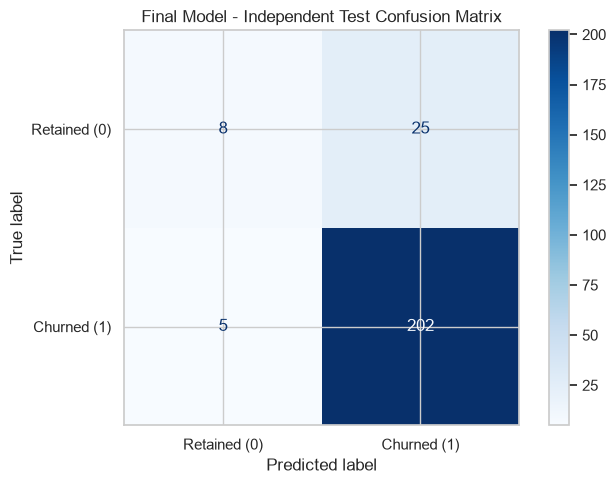

In [99]:
# ==========================================
# 13.4 Final Test Confusion Matrix
# ==========================================

from sklearn.metrics import ConfusionMatrixDisplay

fig, ax = plt.subplots(figsize=(7, 5))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    test_predictions,
    display_labels=[
        "Retained (0)",
        "Churned (1)"
    ],
    cmap="Blues",
    values_format="d",
    ax=ax
)

ax.set_title(
    "Final Model - Independent Test Confusion Matrix"
)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "21_final_test_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [100]:
# ==========================================
# 13.5 Independent Test Top-20% Evaluation
# ==========================================

test_labels = y_test.to_numpy()

# Business contact limit
TEST_CONTACT_RATE = 0.20

test_contact_budget = int(
    np.ceil(len(test_labels) * TEST_CONTACT_RATE)
)

# Rank test customers by predicted churn probability
test_ranked_indices = np.argsort(
    -test_probabilities,
    kind="stable"
)

test_selected_indices = test_ranked_indices[
    :test_contact_budget
]

# Count actual churners
test_captured_churners = int(
    test_labels[test_selected_indices].sum()
)

test_total_churners = int(
    test_labels.sum()
)

# Business targeting metrics
test_precision_at20 = (
    test_captured_churners / test_contact_budget
)

test_recall_at20 = (
    test_captured_churners / test_total_churners
)

test_random_expected = (
    test_contact_budget * test_labels.mean()
)

test_lift_at20 = (
    test_captured_churners / test_random_expected
)

print("FINAL TEST TOP-20% RETENTION ANALYSIS")
print("=" * 55)

print("Total test customers:", len(test_labels))
print("Contact budget:", test_contact_budget)
print("Actual churners:", test_total_churners)

print("\nModel-based targeting:")
print("Churners captured:", test_captured_churners)
print("Precision@20%:", round(test_precision_at20, 4))
print("Recall@20%:", round(test_recall_at20, 4))
print("Lift@20%:", round(test_lift_at20, 4))

print("\nRandom targeting:")
print(
    "Expected churners captured:",
    round(test_random_expected, 2)
)

FINAL TEST TOP-20% RETENTION ANALYSIS
Total test customers: 240
Contact budget: 48
Actual churners: 207

Model-based targeting:
Churners captured: 48
Precision@20%: 1.0
Recall@20%: 0.2319
Lift@20%: 1.1594

Random targeting:
Expected churners captured: 41.4


In [101]:
# ==========================================
# 13.6 Save Final Evaluation Results
# ==========================================

final_test_results.to_csv(
    REPORTS_DIR / "final_test_metrics.csv",
    index=False
)

# Create customer-level test results
test_output = pd.DataFrame({
    "customer_id": df_test["customer_id"].to_numpy(),
    "actual_churn": test_labels,
    "predicted_churn_probability": test_probabilities,
    "predicted_class_0_5": test_predictions
})

# Identify the exact top-20% selected group
test_output["top20_contact_flag"] = 0

test_output.loc[
    test_selected_indices,
    "top20_contact_flag"
] = 1

test_output.to_csv(
    REPORTS_DIR / "final_test_predictions.csv",
    index=False
)

print("Final test results saved successfully!")

Final test results saved successfully!


### 13.7 Final Evaluation Methodology

The calibrated Random Forest was selected as the final research model based on development-stage cross-validation, calibration analysis, and business targeting performance.

The model was fitted using all 960 training observations.

Independent evaluation was performed using the previously untouched test dataset containing 240 observations.

The evaluation included discrimination metrics, threshold-based classification metrics, probability reliability metrics, and business-oriented top-20% targeting performance.

A threshold of 0.50 was used solely to report standard classification metrics.

For the operational retention scenario, customers were ranked by predicted churn probability, and the highest-risk 20% were selected.

This ranking strategy directly reflects the company's contact-capacity constraint.

The final test results were not used to select hyperparameters, change model configurations, or optimize the contact-ranking strategy.

The model remains a research prototype because the temporal availability and reliability of monthly usage information have not been independently verified.

The numerical results and final conclusions will be documented after evaluation.

### 13.8 Final Model Performance and Conclusions

The calibrated Random Forest was evaluated using the independent test dataset containing 240 customers.

#### Final Test Results

| Metric | Score |
|---|---:|
| Accuracy | 0.8750 |
| Balanced Accuracy | 0.6091 |
| Precision | 0.8899 |
| Recall | 0.9758 |
| F1 Score | 0.9309 |
| ROC-AUC | 0.9157 |
| PR-AUC | 0.9851 |
| Brier Score | 0.0805 |
| Log Loss | 0.2539 |

The model demonstrated strong churn-risk discrimination, with ROC-AUC of 0.9157.

At the default classification threshold, churn recall was high, but retained-customer recall remained relatively low at approximately 24%.

#### Final Top-20% Retention Results

- Total test customers: 240
- Contact capacity: 48 customers
- Actual churners: 207
- Churners captured: 48
- Precision@20%: 1.0000
- Recall@20%: 0.2319
- Lift@20%: 1.1594
- Random expected captures: 41.4

The model captured all 48 actual churners within the selected highest-risk group.

This represents approximately 6.6 additional churners compared with random targeting in expectation.

#### Final Decision

The calibrated Random Forest is retained as the final research model.

Its ranking performance and probability calibration support its use as a research prototype for customer churn prioritization.

However, deployment requires verifying that all predictive attributes, particularly monthly internet usage, are reliable and available before the churn outcome.

The model was not modified following independent test evaluation.

In [102]:
# ==========================================
# 14.1 Save Final Trained Model
# ==========================================

import joblib
from pathlib import Path

# Create models folder if necessary
MODELS_DIR = PROJECT_ROOT / "models"

MODELS_DIR.mkdir(
    parents=True,
    exist_ok=True
)

# Model artifact path
MODEL_PATH = MODELS_DIR / "03_model_artifact.joblib"

# Save complete trained model
joblib.dump(
    final_model,
    MODEL_PATH,
    compress=3
)

print("Final trained model saved successfully!")
print("Model location:", MODEL_PATH)

Final trained model saved successfully!
Model location: c:\Users\Wasika\Desktop\Gamage Intern\6.Customer Churn Prediction & Retention Analysis\Customer_Churn_Project\models\03_model_artifact.joblib


In [103]:
# ==========================================
# 14.2 Load and Verify Saved Model
# ==========================================

# Only load model artifacts from trusted sources
loaded_model = joblib.load(MODEL_PATH)

# Use five training observations for verification
sample_customers = X_train.head(5).copy()

# Predictions from original model
original_probabilities = final_model.predict_proba(
    sample_customers
)[:, 1]

# Predictions from loaded model
loaded_probabilities = loaded_model.predict_proba(
    sample_customers
)[:, 1]

# Verify predictions are identical
np.testing.assert_allclose(
    original_probabilities,
    loaded_probabilities,
    rtol=1e-10,
    atol=1e-10
)

verification_df = pd.DataFrame({
    "Original Probability": original_probabilities,
    "Loaded Probability": loaded_probabilities
})

display(verification_df.round(6))

print("Model saved and loaded successfully!")
print("Prediction verification passed!")

,Original Probability,Loaded Probability
0,0.974480,0.974480
1,0.946817,0.946817
2,0.975116,0.975116
3,0.791649,0.791649
4,0.930249,0.930249


Model saved and loaded successfully!
Prediction verification passed!


In [104]:
# ==========================================
# 14.3 Save Model Metadata
# ==========================================

import json
import platform
import sklearn

model_metadata = {
    "project": "Customer Churn Prediction",
    "model_name": "Calibrated Random Forest",
    "model_artifact": MODEL_PATH.name,
    "positive_class": 1,

    "training_customers": len(X_train),
    "test_customers": len(X_test),

    "input_features": X_train.columns.tolist(),

    "excluded_features": DROP_COLUMNS,

    "random_state": RANDOM_STATE,

    "contact_capacity": 0.20,
    "contact_strategy": "Top 20% ranked churn probabilities",

    "calibration_method": "sigmoid",
    "calibration_cv_folds": 3,

    "best_hyperparameters": rf_random_search.best_params_,

    "test_metrics": {
        key: float(value)
        for key, value in final_test_metrics.items()
    },

    "versions": {
        "python": platform.python_version(),
        "scikit_learn": sklearn.__version__,
        "pandas": pd.__version__,
        "numpy": np.__version__,
        "joblib": joblib.__version__
    },

    "limitations": [
        "Monthly usage timing requires verification",
        "Some usage records conflict with internet service categories",
        "Predictions represent associations, not causal effects"
    ]
}

METADATA_PATH = MODELS_DIR / "model_metadata.json"

with open(METADATA_PATH, "w", encoding="utf-8") as file:
    json.dump(
        model_metadata,
        file,
        indent=4
    )

print("Model metadata saved successfully!")

Model metadata saved successfully!


## 14. Model Artifact and Reproducibility

The final fitted calibrated Random Forest pipeline was saved using Joblib.

The model artifact includes feature engineering, numerical and categorical preprocessing, classification, and sigmoid probability calibration.

The saved artifact was reloaded and tested using training observations.

Predictions from the loaded model matched the original model predictions.

A separate metadata file records input features, model hyperparameters, evaluation metrics, package versions, and limitations.

The saved artifact supports reproducible inference when the required Python environment and custom source modules are available.

For operational retention targeting, customers must be ranked by predicted churn probability, and only the highest-risk 20% selected for contact.

## 15. Cleaned Dataset Preparation

### Objective

This section prepares the cleaned dataset required for final submission.

The cleaning procedure is designed to:

1. Preserve original customer records.
2. Standardize categorical text formatting.
3. Validate identifiers and numerical values.
4. Document missing values and unusual observations.
5. Avoid data leakage from global statistical imputation.
6. Export a reproducible cleaned CSV file.

Missing numerical values are intentionally preserved because the trained machine learning pipeline handles imputation using training-only statistics.

Potentially legitimate outliers are retained.

Data-quality anomalies are documented separately instead of silently removing customer observations.

In [105]:
# ==========================================
# 15.1 Load Original Dataset
# ==========================================

raw_df = pd.read_csv(DATA_PATH)

cleaned_df = raw_df.copy(deep=True)

print("Original dataset:", raw_df.shape)
print("Cleaned dataset:", cleaned_df.shape)

print("\nTotal missing cells:",
      cleaned_df.isna().sum().sum())

Original dataset: (1200, 20)
Cleaned dataset: (1200, 20)

Total missing cells: 138


In [106]:
# ==========================================
# 15.2 Standardize Text Formatting
# ==========================================

text_columns = cleaned_df.select_dtypes(
    include=["object", "string"]
).columns

for column in text_columns:

    cleaned_df[column] = (
        cleaned_df[column]
        .astype("string")
        .str.strip()
        .replace("", pd.NA)
    )

print("Text formatting standardized!")

print("\nCategorical columns:")
print(text_columns.tolist())

Text formatting standardized!

Categorical columns:
['customer_id', 'contract_type', 'internet_service', 'region', 'payment_method', 'paperless_billing', 'dependents', 'support_plan', 'tech_support']


In [107]:
# ==========================================
# 15.3 Validate Data Quality
# ==========================================

validation_checks = {
    "Missing customer IDs":
        cleaned_df["customer_id"].isna().sum(),

    "Duplicate customer IDs":
        cleaned_df["customer_id"].duplicated().sum(),

    "Invalid churn labels":
        (~cleaned_df["churn"].isin([0, 1])).sum(),

    "Invalid senior citizen flags":
        (~cleaned_df["senior_citizen"].isin([0, 1])).sum(),

    "Invalid ages":
        (~cleaned_df["age"].between(0, 120)).sum(),

    "Invalid tenure":
        (cleaned_df["tenure_months"] < 0).sum(),

    "Negative monthly charges":
        (cleaned_df["monthly_charges"] < 0).sum(),

    "Negative total charges":
        (cleaned_df["total_charges"] < 0).sum(),

    "Negative usage":
        (cleaned_df["monthly_usage_gb"] < 0).sum(),

    "Invalid satisfaction scores":
        (
            cleaned_df["satisfaction_score"].notna()
            & ~cleaned_df["satisfaction_score"].between(1, 10)
        ).sum(),

    "Invalid discounts":
        (
            cleaned_df["discount_pct"].notna()
            & ~cleaned_df["discount_pct"].between(0, 100)
        ).sum()
}

validation_df = pd.DataFrame(
    validation_checks.items(),
    columns=["Validation Check", "Invalid Records"]
)

display(validation_df)

if validation_df["Invalid Records"].sum() > 0:
    raise ValueError(
        "Unexpected invalid values found. Review before exporting."
    )

print("All basic validation checks passed!")

,Validation Check,Invalid Records
0,Missing customer IDs,0
1,Duplicate customer IDs,0
2,Invalid churn labels,0
3,Invalid senior citizen flags,0
4,Invalid ages,0
5,Invalid tenure,0
6,Negative monthly charges,0
7,Negative total charges,0
8,Negative usage,0
9,Invalid satisfaction scores,0


All basic validation checks passed!


In [108]:
# ==========================================
# 15.4 Data Quality Flags
# ==========================================

quality_flags = pd.DataFrame({
    "customer_id": cleaned_df["customer_id"]
})

quality_flags["missing_field_count"] = (
    cleaned_df.isna().sum(axis=1)
)

quality_flags["usage_service_mismatch"] = (
    (cleaned_df["internet_service"] == "No")
    & (cleaned_df["monthly_usage_gb"] > 0)
).astype(int)

# Approximate total charges consistency check
expected_total = (
    cleaned_df["monthly_charges"]
    * cleaned_df["tenure_months"]
)

relative_difference = (
    (cleaned_df["total_charges"] - expected_total)
    / expected_total.replace(0, np.nan)
).abs()

quality_flags["billing_difference_flag"] = (
    relative_difference > 0.25
).astype(int)

print("DATA QUALITY SUMMARY")
print("=" * 50)

print(
    "Customers with missing fields:",
    int((quality_flags["missing_field_count"] > 0).sum())
)

print(
    "Usage/service mismatches:",
    quality_flags["usage_service_mismatch"].sum()
)

print(
    "Large billing differences:",
    quality_flags["billing_difference_flag"].sum()
)

display(quality_flags.head())

DATA QUALITY SUMMARY
Customers with missing fields: 132
Usage/service mismatches: 147
Large billing differences: 5


,customer_id,missing_field_count,usage_service_mismatch,billing_difference_flag
0,CUST100001,0,0,0
1,CUST100002,0,0,0
2,CUST100003,1,0,0
3,CUST100004,0,0,0
4,CUST100005,0,0,0


In [109]:
# ==========================================
# 15.5 Export Cleaned Dataset
# ==========================================

PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"

PROCESSED_DIR.mkdir(
    parents=True,
    exist_ok=True
)

CLEANED_DATA_PATH = (
    PROCESSED_DIR / "02_cleaned_dataset.csv"
)

# Save all records
cleaned_df.to_csv(
    CLEANED_DATA_PATH,
    index=False
)

# Save anomaly flags separately
quality_flags.to_csv(
    REPORTS_DIR / "data_quality_flags.csv",
    index=False
)

print("Cleaned dataset saved successfully!")
print("Location:", CLEANED_DATA_PATH)

print("\nDataset shape:", cleaned_df.shape)
print("Remaining missing cells:",
      cleaned_df.isna().sum().sum())

Cleaned dataset saved successfully!
Location: c:\Users\Wasika\Desktop\Gamage Intern\6.Customer Churn Prediction & Retention Analysis\Customer_Churn_Project\data\processed\02_cleaned_dataset.csv

Dataset shape: (1200, 20)
Remaining missing cells: 138


In [110]:
# ==========================================
# 15.6 Verify Exported Dataset
# ==========================================

verified_df = pd.read_csv(CLEANED_DATA_PATH)

assert verified_df.shape == (1200, 20)

assert verified_df["customer_id"].is_unique

assert verified_df.columns.tolist() == raw_df.columns.tolist()

assert verified_df.isna().sum().sum() == 138

assert verified_df["churn"].isin([0, 1]).all()

print("Cleaned dataset verification passed!")
print("Rows:", len(verified_df))
print("Columns:", len(verified_df.columns))

Cleaned dataset verification passed!
Rows: 1200
Columns: 20


### 15.7 Data Cleaning Decisions and Final Output

The cleaned dataset was prepared from a fresh copy of the original CSV file.

The procedure standardized text formatting, verified customer identifiers, checked numerical validity, and documented unusual observations.

No customer records were removed.

The original dataset contained 1,200 customers, 20 columns, and 138 missing cells.

Missing values were preserved because statistical imputation is already performed within the machine learning pipeline using training-derived parameters.

Outliers were retained because unusual customer behavior may provide useful predictive information.

A separate quality-flag dataset was generated to document inconsistencies involving internet usage and service status, together with unusually large differences in estimated cumulative charges.

These observations were flagged rather than automatically corrected because the available information does not establish that they are erroneous.

The final cleaned dataset contains 1,200 customer records and 20 original variables.

**Output:** data/processed/02_cleaned_dataset.csv

**Additional Audit Output:** reports/data_quality_flags.csv

The cleaned dataset is provided as a reproducible data-preparation artifact. It was not used to revise the already completed independent test evaluation.